# 04: The Recommender (KNN) and the App Models

**Run order:** `Coffee_EDA` (cleaning and EDA) → `02_Modeling` → `03_Clustering` → **this notebook** → `05_Evaluation`.
This notebook builds everything the app needs: it reads the clean data, takes the acidity and bitterness levels from `02_Modeling`, trains the models that fill the gaps, builds the KNN recommender, tunes and tests it, and saves the files in `models/` and `data/app_coffees.csv`.

## 20. Problem Definition

**The problem:** there are 569 specialty coffees from 71 Saudi roasters, spread over 51 websites, written in Arabic and English, and many details are missing. A buyer can't easily answer *"which bag will taste like what I like?"*

**Our solution: مَذاق (Mathaq).** The user gets the 5 best coffees, with a reason for each one, in three ways:

1. **Write the request in their own words** (Arabic or English): *"أبي شي فاكهي للـ V60 بأقل من 70 ريال"*
2. **Pick a coffee they liked** and say what they liked about it (body, acidity, flavor, price...).
3. **Pick a "coffee personality"** card if they don't know coffee words.

**Is it supervised or unsupervised?** Both, and they work together:

- The recommender itself is **unsupervised: K-Nearest Neighbors (KNN)**. A supervised recommender would need a label like *"user X liked coffee Y"*, and our data has no ratings or purchases. KNN needs no labels: every coffee is a point, the request is a point, and we return the 5 closest coffees.
- **Supervised models** fill the gaps in the KNN features, where the data has labels for some rows.
- **K-Means (unsupervised)** groups the coffees into personality cards for beginners.

| Part | Type | Why we need it |
|---|---|---|
| Recommender | **Unsupervised: K-Nearest Neighbors** (cosine distance) | finds the 5 coffees closest to the request |
| Flavor families for the 42 coffees with no notes | Supervised: Random Forest, multi-label | they become part of the KNN features |
| Body level for the 397 coffees without it | Supervised: Random Forest, 3 classes | its probabilities become the body feature of KNN |
| Coffee personalities | Unsupervised: K-Means | cards for beginners |
| Acidity and bitterness levels | Taste scores from `02_Modeling` (stated value when the roaster gives it) | very few coffees state them, so there is little to learn from |

## 21. Load the Clean Data and Prepare the Features

In [1]:
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score, confusion_matrix, silhouette_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

SAGE, GOLD, ROSE, BROWN = "#6B9E78", "#C9A24D", "#C07A7A", "#6F4E37"
report = {}  # numbers we show in the presentation

I start from the clean file saved at the end of `Coffee_EDA` (section 19).

In [2]:
df = pd.read_csv("../data/saudi_specialty_coffee_beans_clean.csv")

families = ["fruity", "citrus", "floral", "chocolate", "nutty", "caramel_sweet", "spice", "tea"]
family_columns = ["note_" + f for f in families]
has_notes = df["n_tasting_notes"] > 0

notes_list = []
for text in df["tasting_notes"]:
    if text == "Unknown":
        notes_list.append([])
    else:
        notes_list.append(text.split("; "))
df["notes_list"] = notes_list

print("Coffees:", len(df))
print("With tasting notes:", has_notes.sum(), "| without:", (~has_notes).sum())
print("With a known body level:", (df["body_level"] != "Unknown").sum())

Coffees: 569
With tasting notes: 527 | without: 42
With a known body level: 172


The models need numbers, so I turn the useful columns into numeric features:

- **Origin, process, product type and roast level** become 0/1 columns (one-hot). Countries with fewer than 5 coffees are grouped as "Other", so the model doesn't learn from 1 or 2 rows.
- **Altitude** in km, and the **log of the price per 100 g**. I use the log because a few coffees cost 4 to 5 times the median, and the log stops them from dominating.

In [3]:
country_counts = df["origin_country"].value_counts()
top_countries = list(country_counts[country_counts >= 5].index)


def make_features(data):
    country = data["origin_country"].where(data["origin_country"].isin(top_countries), "Other")
    parts = [
        pd.get_dummies(country, prefix="origin"),
        pd.get_dummies(data["process"], prefix="process"),
        pd.get_dummies(data["product_type"], prefix="type"),
        pd.get_dummies(data["roast_level"], prefix="roast"),
        data[["is_infused", "suits_espresso", "suits_filter"]],
    ]
    features = pd.concat(parts, axis=1).astype(float)
    features["altitude_km"] = data["altitude_mean_m"] / 1000
    features["log_price_100g"] = np.log(data["price_per_100g_sar"])
    return features


X_meta = make_features(df)
print("Feature table:", X_meta.shape)

Feature table: (569, 43)


## 22. Model 1: Flavor Families for the Coffees With No Notes

42 coffees have no tasting notes, so the recommender can't compare them. Can we guess their flavor from the rest of their information (origin, process, altitude, price...)?

This is **multi-label classification**: one coffee can be fruity *and* chocolatey at the same time, so I train one yes/no model per family. I predict the 6 main families. Spice (14 coffees) and tea (21) are too rare to learn.

**How I test it fairly:** `GroupKFold` by **roaster** with 5 folds. Each roaster writes notes in its own style, so if the same roaster is in both train and test, the score looks better than it really is. Here the model is always tested on roasters it has never seen.

**Metric: ROC-AUC.** The families are imbalanced (74% of coffees are fruity but only 17% citrus). AUC measures how well the model *ranks* yes above no: 0.5 = random guessing, 1.0 = perfect. I also show F1 at the 0.5 threshold.

In [4]:
target_families = ["fruity", "citrus", "floral", "chocolate", "nutty", "caramel_sweet"]
X_train = X_meta[has_notes]
groups = df.loc[has_notes, "roaster"]

flavor_models = {
    "Baseline (always the average)": DummyClassifier(strategy="prior"),
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(C=0.3, class_weight="balanced", max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                            class_weight="balanced_subsample", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=0.05, random_state=42),
}

rows = []
for model_name, model in flavor_models.items():
    for family in target_families:
        y = df.loc[has_notes, "note_" + family]
        prob = cross_val_predict(model, X_train, y, cv=GroupKFold(n_splits=5), groups=groups,
                                 method="predict_proba")[:, 1]
        rows.append({"model": model_name, "family": family,
                     "roc_auc": roc_auc_score(y, prob), "f1": f1_score(y, prob >= 0.5)})

flavor_results = pd.DataFrame(rows)
flavor_results.pivot(index="family", columns="model", values="roc_auc").round(3)

model,Baseline (always the average),Gradient Boosting,Logistic Regression,Random Forest
family,,,,
caramel_sweet,0.446,0.519,0.515,0.541
chocolate,0.451,0.688,0.673,0.711
citrus,0.437,0.527,0.546,0.591
floral,0.439,0.637,0.669,0.676
fruity,0.426,0.848,0.834,0.860
nutty,0.386,0.737,0.759,0.770


In [5]:
flavor_summary = flavor_results.groupby("model")[["roc_auc", "f1"]].mean().round(3)
flavor_summary

,roc_auc,f1
model,,
Baseline (always the average),0.431,0.142
Gradient Boosting,0.659,0.377
Logistic Regression,0.666,0.506
Random Forest,0.691,0.498


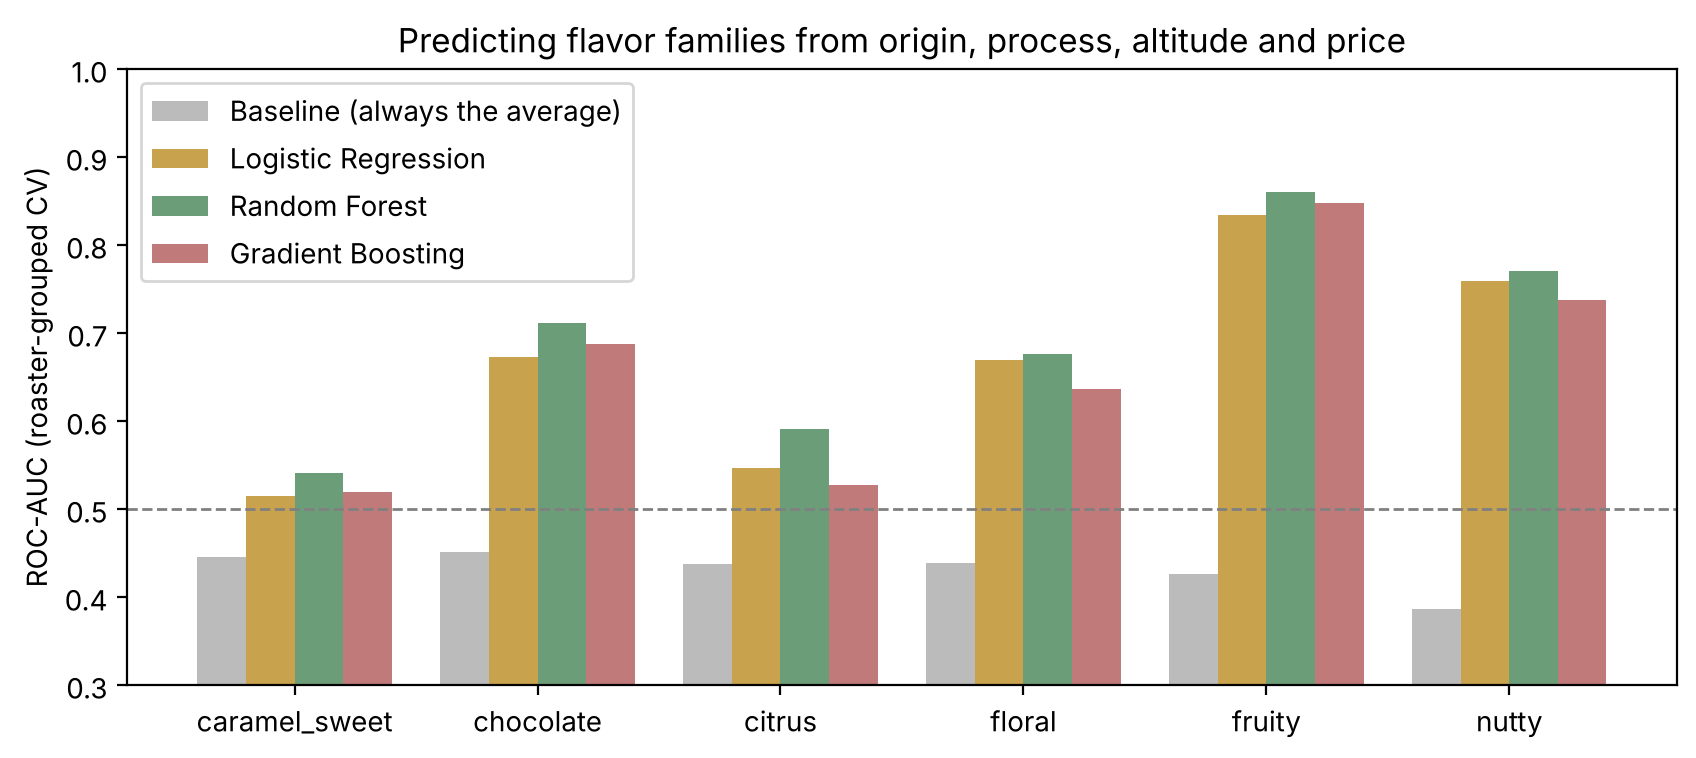

In [6]:
pivot = flavor_results.pivot(index="family", columns="model", values="roc_auc")[list(flavor_models)]
x = np.arange(len(pivot))
colors = ["#BBBBBB", GOLD, SAGE, ROSE]

plt.figure(figsize=(10, 4))
for k, model_name in enumerate(pivot.columns):
    plt.bar(x + (k - 1.5) * 0.2, pivot[model_name], width=0.2, label=model_name, color=colors[k])
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.xticks(x, pivot.index)
plt.ylabel("ROC-AUC (roaster-grouped CV)")
plt.ylim(0.3, 1)
plt.title("Predicting flavor families from origin, process, altitude and price")
plt.legend()
plt.show()

**Results:** Random Forest has the best average AUC (0.69, vs 0.67 for Logistic Regression and 0.66 for Gradient Boosting). It is good for **fruity** (0.86) and **nutty** (0.77), fair for **chocolate** and **floral** (about 0.7), and weak for **citrus** and **caramel** (under 0.6), because those depend on the roaster's words more than on the origin. The baseline gives the same answer to everyone, so its AUC sits around 0.5 or a bit below.

**My choice: Random Forest.** It learns combinations like *natural process + Ethiopia + high altitude → fruity* without me writing them by hand. Because the score is only fair, the app always labels these flavors as **"predicted"**.

In [7]:
flavor_final_models = {}
predicted_family = pd.DataFrame(0, index=df.index[~has_notes], columns=families)
all_probs = pd.DataFrame(index=df.index[~has_notes])

for family in target_families:
    model = RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                   class_weight="balanced_subsample", random_state=42)
    model.fit(X_train, df.loc[has_notes, "note_" + family])
    flavor_final_models[family] = model
    prob = model.predict_proba(X_meta[~has_notes])[:, 1]
    predicted_family[family] = (prob >= 0.5).astype(int)
    all_probs[family] = prob

# every coffee gets at least its most likely family
for i in predicted_family.index:
    if predicted_family.loc[i].sum() == 0:
        predicted_family.loc[i, all_probs.loc[i].idxmax()] = 1

example = df.loc[~has_notes, ["coffee_name", "origin_country", "process"]].copy()
example["predicted_families"] = [", ".join(f for f in families if predicted_family.loc[i, f] == 1)
                                 for i in example.index]
example.head(8)

,coffee_name,origin_country,process,predicted_families
16,3Bean Saudi Coffee Beans 250g,Multiple,Mixed,"chocolate, nutty"
57,Chinese Crop,China,Anaerobic,fruity
75,Qasr Al-Murabba Blend 250g,Multiple,Unknown,"chocolate, nutty"
88,Black Knight Chaffee El Salvador 250G,El Salvador,Unknown,"fruity, chocolate"
89,Black Knight Minas Brazil,Brazil,Unknown,"chocolate, nutty, caramel_sweet"
100,Abena - Ethiopian Natural,Ethiopia,Natural,"fruity, floral"
101,Blawan - Indonesian Washed,Indonesia,Washed,"floral, chocolate"
103,Roricha | Ethiopia Anaerobic,Ethiopia,Anaerobic,"fruity, floral"


In [8]:
# final family flags: the real ones, or the predicted ones for the 42 coffees
family_final = df[family_columns].copy()
family_final.columns = families
family_final.loc[~has_notes] = predicted_family[families].values

report["flavor_model"] = {
    "auc_by_model": flavor_summary["roc_auc"].to_dict(),
    "f1_by_model": flavor_summary["f1"].to_dict(),
    "auc_by_family": pivot.round(3).to_dict(),
    "chosen": "Random Forest",
    "n_predicted": int((~has_notes).sum()),
}

## 23. Model 2: Body Level

Only 172 coffees say their body (how heavy the coffee feels in the mouth). The other 397 are Unknown. Users often ask for "قوام ثقيل" (full body), so I try to predict it.

- I merge the 2 **Medium-Full** coffees into **Full**, so the classes are Light / Medium / Full.
- The classes are imbalanced (Full 94, Medium 61, Light 17), so I use **macro F1**: it gives each class the same weight. Accuracy would reward a model that always says "Full".
- Same fair test as before: grouped by roaster (`StratifiedGroupKFold`), repeated with 5 different shuffles, and I report the average.
- Features: the meta features + the 8 flavor families + one 0/1 column for every tasting note that appears at least 3 times.
- I also measure **log loss**: how good the model's *probabilities* are (lower = better). This matters because the app will only show a body when the model is sure.

In [9]:
df["body_target"] = df["body_level"].replace({"Medium-Full": "Full"})
labeled = df["body_target"] != "Unknown"
print(df.loc[labeled, "body_target"].value_counts())

note_counts = pd.Series([note for notes in df["notes_list"] for note in notes]).value_counts()
common_notes = list(note_counts[note_counts >= 3].index)

note_table = pd.DataFrame(0, index=df.index, columns=["has_" + n for n in common_notes])
for i in df.index:
    for note in df.loc[i, "notes_list"]:
        if note in common_notes:
            note_table.loc[i, "has_" + note] = 1

X_body = pd.concat([X_meta, family_final, note_table], axis=1)
print("Body features:", X_body.shape)

body_target
Full      94
Medium    61
Light     17
Name: count, dtype: int64
Body features: (569, 139)


In [10]:
body_models = {
    "Baseline: always the most common": DummyClassifier(strategy="most_frequent"),
    "Baseline: random guess": DummyClassifier(strategy="stratified", random_state=0),
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(C=0.1, class_weight="balanced", max_iter=3000)),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced",
                                            random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=0.05, random_state=42),
    "Naive Bayes": BernoulliNB(),
}

X_lab = X_body[labeled]
y_lab = df.loc[labeled, "body_target"]
g_lab = df.loc[labeled, "roaster"]

from sklearn.metrics import log_loss

classes = sorted(y_lab.unique())
rows, cv_probs = [], {}
for model_name, model in body_models.items():
    f1s, accs, losses = [], [], []
    for seed in range(5):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        prob = cross_val_predict(model, X_lab, y_lab, cv=cv, groups=g_lab, method="predict_proba")
        pred = np.array(classes)[prob.argmax(axis=1)]
        f1s.append(f1_score(y_lab, pred, average="macro"))
        accs.append(accuracy_score(y_lab, pred))
        clipped = np.clip(prob, 0.01, 1)  # avoid log(0) for the baselines
        losses.append(log_loss(y_lab, clipped / clipped.sum(axis=1, keepdims=True), labels=classes))
        if seed == 0:
            cv_probs[model_name] = prob
    rows.append({"model": model_name, "macro_f1": np.mean(f1s), "f1_std": np.std(f1s),
                 "accuracy": np.mean(accs), "log_loss": np.mean(losses)})

body_results = pd.DataFrame(rows).set_index("model").round(3)
body_results

,macro_f1,f1_std,accuracy,log_loss
model,,,,
Baseline: always the most common,0.236,0.000,0.547,2.108
Baseline: random guess,0.344,0.027,0.405,2.761
Logistic Regression,0.392,0.020,0.505,1.304
Random Forest,0.376,0.013,0.497,1.028
Gradient Boosting,0.386,0.017,0.570,1.015
Naive Bayes,0.392,0.007,0.579,1.297


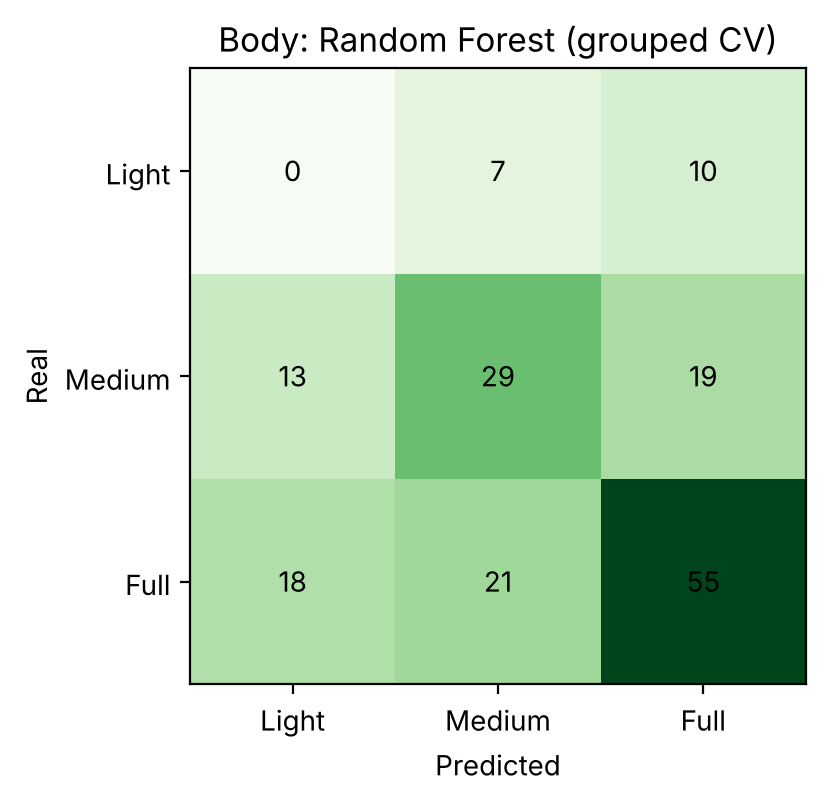

In [11]:
body_probs = cv_probs["Random Forest"]
body_pred = np.array(classes)[body_probs.argmax(axis=1)]

order = ["Light", "Medium", "Full"]
cm = confusion_matrix(y_lab, body_pred, labels=order)

plt.figure(figsize=(4.5, 4))
plt.imshow(cm, cmap="Greens")
for a in range(3):
    for b in range(3):
        plt.text(b, a, cm[a, b], ha="center", va="center")
plt.xticks(range(3), order)
plt.yticks(range(3), order)
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.title("Body: Random Forest (grouped CV)")
plt.show()

**Honest result:** the real models reach a macro F1 of only about 0.38 to 0.39, against 0.24 for "always Full" and 0.34 for a random guess. So body **can't be predicted reliably for every coffee**.

The main reason is in the labels themselves: roasters use the word "body" differently. For example, Alwal Albari calls 7 of its 8 coffees "Full". So the same kind of coffee gets different labels from different roasters.

**My choice: Random Forest.** The real models have almost the same macro F1, so I chose by what the app needs. The app only shows a body when the model is sure, so the *probabilities* must be trustworthy. Random Forest and Gradient Boosting have the best log loss (about 1.02 to 1.03, vs 1.3 for Logistic Regression and Naive Bayes). They are practically tied, so I keep Random Forest, the same model type as the flavor model.

**How the app uses it:** two ways.
1. **On the coffee card**, we show a predicted body only when the model is at least 50% sure, always written as *"predicted (xx%)"*.
2. **Inside KNN (section 27)**, we use the model's *probabilities* (e.g. 20% Light, 50% Medium, 30% Full) as the body feature, so an unsure guess only counts a little.

Let's check what each confidence rule gives:

In [12]:
confidence = body_probs.max(axis=1)
rows = []
for threshold in [0.0, 0.4, 0.5, 0.6, 0.7]:
    keep = confidence >= threshold
    rows.append({"min_confidence": threshold, "coverage": keep.mean(),
                 "accuracy_when_shown": accuracy_score(y_lab[keep], body_pred[keep]) if keep.sum() else np.nan})
threshold_table = pd.DataFrame(rows).round(3)
threshold_table

,min_confidence,coverage,accuracy_when_shown
0,0.0,1.000,0.488
1,0.4,0.651,0.554
2,0.5,0.192,0.758
3,0.6,0.047,0.625
4,0.7,0.006,1.000


When Random Forest is at least **50% sure**, it is right about **3 times out of 4**, against 55% for always saying "Full". It is that sure for about 1 coffee in 5. So the app shows those predictions and leaves the rest as Unknown, instead of showing weak guesses.

In [13]:
body_model = RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced", random_state=42)
body_model.fit(X_lab, y_lab)

unknown_body = ~labeled
probs = body_model.predict_proba(X_body[unknown_body])
df["body_final"] = df["body_target"].where(labeled, None)
df["body_is_predicted"] = False
df["body_confidence"] = np.nan

for row, i in enumerate(df.index[unknown_body]):
    best = probs[row].argmax()
    df.loc[i, "body_confidence"] = round(probs[row][best], 2)
    if probs[row][best] >= 0.5:
        df.loc[i, "body_final"] = body_model.classes_[best]
        df.loc[i, "body_is_predicted"] = True

print("Real body:", labeled.sum())
print("Predicted body (shown, 50%+ sure):", df["body_is_predicted"].sum())
print("Still unknown:", df["body_final"].isna().sum())

Real body: 172
Predicted body (shown, 50%+ sure): 74
Still unknown: 323


In [14]:
report["body_model"] = {
    "results": body_results.reset_index().to_dict(orient="records"),
    "threshold_table": threshold_table.to_dict(orient="records"),
    "confusion": cm.tolist(), "labels": order, "chosen": "Random Forest",
    "n_real": int(labeled.sum()), "n_predicted_shown": int(df["body_is_predicted"].sum()),
}

## 24. Acidity and Bitterness (from 02_Modeling)

Users ask for things like *"حموضته خفيفة"* or *"مرارته عالية"*, but very few coffees state these: 72 state their acidity and only 21 their bitterness. In `02_Modeling`, Raghad built a **taste score** for each one from the notes, the origin, the process, the altitude and the roast, and checked it against the coffees that do state it (Spearman: acidity 0.26 with p = 0.03, so weak but in the right direction). Her rule:

1. If the roaster **states** the value, use it.
2. Otherwise, use the score: the lowest third = Low, the middle third = Medium, the top third = High, marked as **estimated**.

I take acidity and bitterness from her file. For **body** I keep my Random Forest from section 23, because it gives probabilities, and the app only shows a predicted body when the model is sure.

In [15]:
team = pd.read_csv("../data/coffee_enriched.csv")  # written by 02_Modeling and 03_Clustering
assert (team["bean_id"].values == df["bean_id"].values).all(), "run Coffee_EDA, 02 and 03 first"

for col in ["acidity_level", "acidity_is_estimated", "acidity_score",
            "bitterness_level", "bitterness_is_estimated", "bitterness_score"]:
    df[col] = team[col].values

summary = pd.DataFrame({
    "acidity": df["acidity_level"].value_counts(),
    "bitterness": df["bitterness_level"].value_counts(),
}).loc[["Low", "Medium", "High"]]
summary.loc["stated by the roaster"] = [int((df["acidity_is_estimated"] == 0).sum()),
                                        int((df["bitterness_is_estimated"] == 0).sum())]
summary

,acidity,bitterness
Low,181,239
Medium,207,146
High,181,184
stated by the roaster,72,21


Because most of these levels are estimates, the app labels them as estimated, and in the KNN they get the same small weight as the other attributes (tuned in section 28).

In [16]:
report["acidity"] = {"counts": df["acidity_level"].value_counts().to_dict(),
                     "stated": int((df["acidity_is_estimated"] == 0).sum())}
report["bitterness"] = {"counts": df["bitterness_level"].value_counts().to_dict(),
                        "stated": int((df["bitterness_is_estimated"] == 0).sum())}

## 25. Model 3: Coffee Personalities with K-Means (Unsupervised)

For users who don't know coffee words, we show a few "personality" cards. To find them, I cluster the coffees by their **8 flavor families**.

I learn the clusters from the **527 coffees with real notes** only. The 42 predicted coffees are then put in the nearest cluster. This way our own guesses don't shape the personalities.

**Choosing k:** I try k = 2 to 8 and look at the **inertia** (elbow) and the **silhouette score** (how well separated the groups are, from -1 to 1, higher is better).

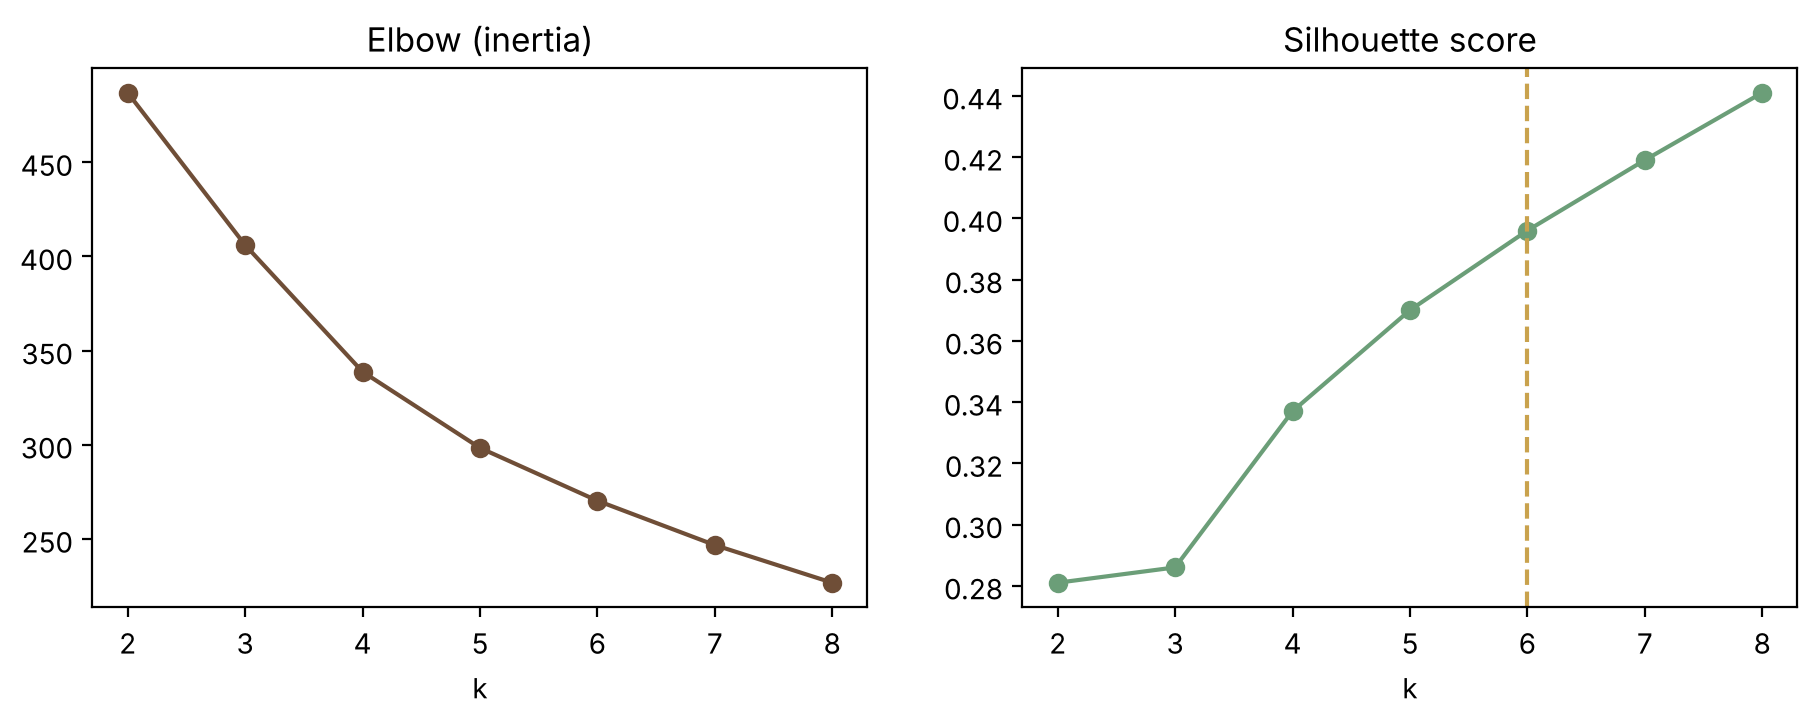

,k,inertia,silhouette
0,2,486.912,0.281
1,3,406.075,0.286
2,4,338.808,0.337
3,5,298.380,0.370
4,6,270.339,0.396
5,7,246.796,0.419
6,8,226.807,0.441


In [17]:
X_cluster = family_final.loc[has_notes, families].values.astype(float)

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_cluster)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X_cluster, km.labels_)})
k_table = pd.DataFrame(rows).round(3)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(k_table["k"], k_table["inertia"], marker="o", color=BROWN)
axes[0].set_title("Elbow (inertia)")
axes[1].plot(k_table["k"], k_table["silhouette"], marker="o", color=SAGE)
axes[1].axvline(6, color=GOLD, linestyle="--")
axes[1].set_title("Silhouette score")
for ax in axes:
    ax.set_xlabel("k")
plt.show()
k_table

The silhouette keeps going up with k, because yes/no data can always be split into smaller exact combinations. So the silhouette alone can't choose k.

My rule: the app shows the personalities as cards, and **more than 6 cards is too many choices** for a beginner. So I take the best silhouette with k ≤ 6, which is **k = 6**.

In [18]:
kmeans = KMeans(n_clusters=6, n_init=20, random_state=42).fit(X_cluster)
all_labels = kmeans.predict(family_final[families].values.astype(float))  # the 42 go to the nearest cluster

centers = pd.DataFrame(kmeans.cluster_centers_, columns=families).round(2)
centers["n_coffees"] = np.bincount(all_labels)
centers

,fruity,citrus,floral,chocolate,nutty,caramel_sweet,spice,tea,n_coffees
0,0.93,0.0,0.02,0.25,0.08,1.00,0.02,0.01,86
1,0.80,1.0,0.25,0.29,0.13,0.27,-0.00,0.04,80
2,0.91,0.0,0.11,1.00,0.15,-0.00,0.05,0.09,89
3,0.95,0.0,1.00,-0.00,0.09,0.25,0.02,0.09,67
4,0.95,0.0,0.00,0.00,0.10,-0.00,0.02,0.03,123
5,0.09,0.1,0.07,0.83,0.76,0.72,0.05,-0.00,124


Each cluster has a clear "main" flavor, so I name them with simple rules on the centers. I also order them from the lightest taste to the heaviest, so the cards make sense on screen.

In [19]:
def profile_key(center):
    c = dict(zip(families, center))
    if c["nutty"] > 0.5:
        return "chocolate_nutty"
    if c["citrus"] > 0.5:
        return "citrus"
    if c["floral"] > 0.5:
        return "floral"
    if c["chocolate"] > 0.5:
        return "fruity_chocolate"
    if c["caramel_sweet"] > 0.5:
        return "sweet_caramel"
    return "juicy_fruity"


profile_text = {
    "juicy_fruity": {"name": {"en": "Juicy & fruity", "ar": "فاكهي"},
                     "description": {"en": "Berries, peach and tropical fruit. Bright, fun and easy to love.",
                                     "ar": "توت وخوخ وفواكه استوائية. طعم مبهج وواضح."}},
    "citrus": {"name": {"en": "Bright & citrusy", "ar": "حمضي ومنعش"},
               "description": {"en": "Orange, tangerine and lemon. Fresh, with a lively acidity.",
                               "ar": "برتقال ويوسفي وليمون. منعش وحموضته واضحة."}},
    "floral": {"name": {"en": "Floral & delicate", "ar": "زهري وناعم"},
               "description": {"en": "Jasmine and stone fruit. Light and elegant, a bit like tea.",
                               "ar": "ياسمين وخوخ. خفيف وأنيق، قريب من الشاي."}},
    "sweet_caramel": {"name": {"en": "Sweet & caramel", "ar": "حلو وكراميل"},
                      "description": {"en": "Caramel, brown sugar and honey with soft fruit.",
                                      "ar": "كراميل وسكر بني وعسل مع لمسة فواكه."}},
    "fruity_chocolate": {"name": {"en": "Fruity chocolate", "ar": "شوكولاتة وفاكهة"},
                         "description": {"en": "Dark chocolate with grape and red fruit.",
                                         "ar": "شوكولاتة داكنة مع عنب وفواكه حمراء."}},
    "chocolate_nutty": {"name": {"en": "Chocolate & nutty", "ar": "شوكولاتة ومكسرات"},
                        "description": {"en": "Classic and comforting: chocolate, caramel and nuts.",
                                        "ar": "كلاسيكي ومريح: شوكولاتة وكراميل ومكسرات."}},
}
display_order = ["juicy_fruity", "citrus", "floral", "sweet_caramel", "fruity_chocolate", "chocolate_nutty"]

cluster_key = {c: profile_key(kmeans.cluster_centers_[c]) for c in range(6)}
assert len(set(cluster_key.values())) == 6, "two clusters got the same name"
cluster_to_profile = {c: display_order.index(key) for c, key in cluster_key.items()}
df["profile_id"] = [cluster_to_profile[c] for c in all_labels]

profiles = []
for key in display_order:
    pid = display_order.index(key)
    cluster = [c for c, k in cluster_key.items() if k == key][0]
    members = df[df["profile_id"] == pid]
    real_notes = [n for i in members.index if has_notes[i] for n in df.loc[i, "notes_list"]]
    top_notes = list(pd.Series(real_notes).value_counts().head(4).index)
    profiles.append({"profile_id": pid, "key": key, "name": profile_text[key]["name"],
                     "description": profile_text[key]["description"], "top_notes": top_notes,
                     "n_coffees": int(len(members)),
                     "centroid": [round(float(v), 4) for v in kmeans.cluster_centers_[cluster]]})

pd.DataFrame([{"id": p["profile_id"], "name": p["name"]["en"], "coffees": p["n_coffees"],
               "top notes": ", ".join(p["top_notes"])} for p in profiles])

,id,name,coffees,top notes
0,0,Juicy & fruity,123,"Strawberry, Berries, Tropical fruits, Peach"
1,1,Bright & citrusy,80,"Orange, Chocolate, Floral, Tangerine"
2,2,Floral & delicate,67,"Floral, Jasmine, Peach, Strawberry"
3,3,Sweet & caramel,86,"Caramel, Brown sugar, Chocolate, Vanilla"
4,4,Fruity chocolate,89,"Chocolate, Dark chocolate, Grape, Cocoa"
5,5,Chocolate & nutty,124,"Caramel, Chocolate, Nuts, Hazelnut"


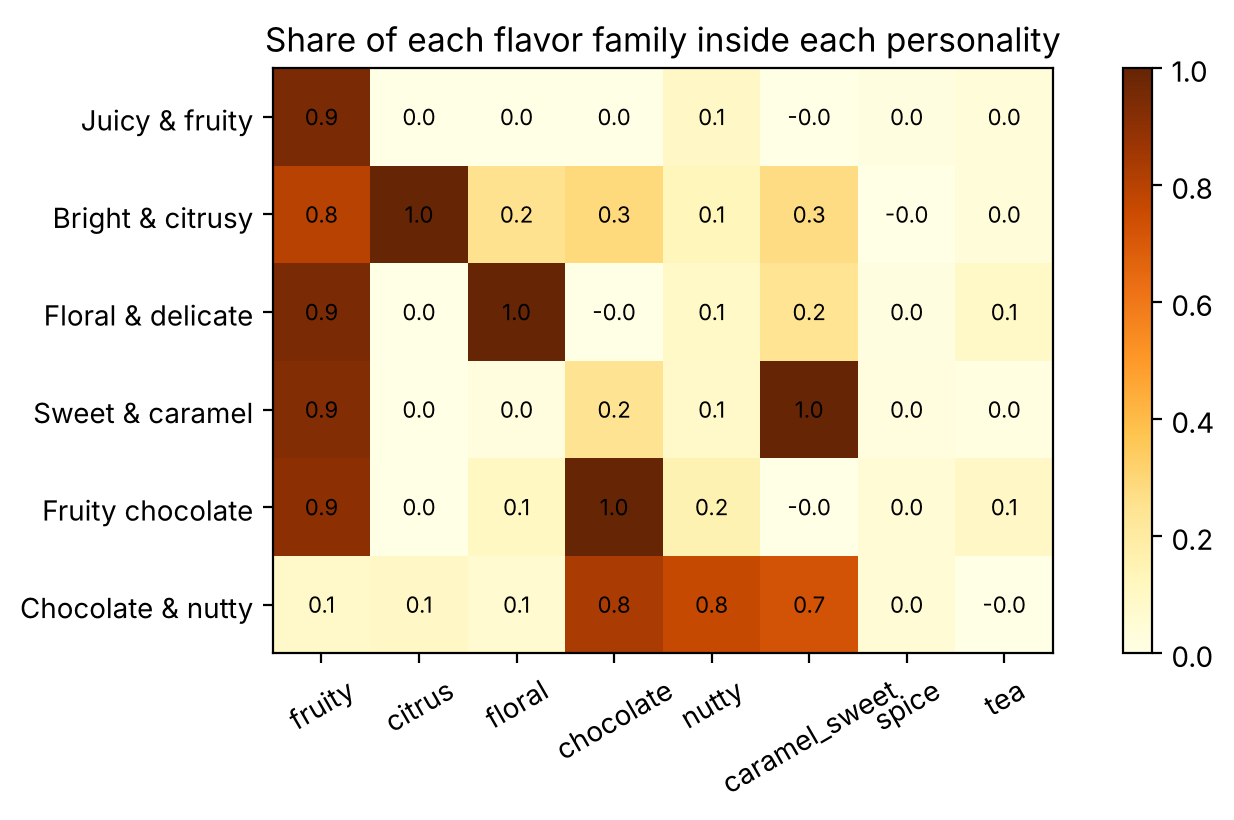

In [20]:
heat = pd.DataFrame([p["centroid"] for p in profiles], columns=families,
                    index=[p["name"]["en"] for p in profiles])

plt.figure(figsize=(9, 3.8))
plt.imshow(heat.values, cmap="YlOrBr", vmin=0, vmax=1)
plt.xticks(range(len(families)), families, rotation=30)
plt.yticks(range(len(heat)), heat.index)
for a in range(heat.shape[0]):
    for b in range(heat.shape[1]):
        plt.text(b, a, f"{heat.values[a, b]:.1f}", ha="center", va="center", fontsize=8)
plt.title("Share of each flavor family inside each personality")
plt.colorbar()
plt.show()

In [21]:
report["kmeans"] = {"k_table": k_table.to_dict(orient="records"), "chosen_k": 6,
                    "profiles": [{k: p[k] for k in ["profile_id", "key", "name", "top_notes", "n_coffees", "centroid"]}
                                 for p in profiles]}

## 26. Save the Enriched Data and the Models

The API reads one enriched file with everything the models added. It doesn't need scikit-learn at runtime, so it starts fast on the server. I also translate the product links back to readable text to make the file smaller (the API encodes them again).

The app is fully in Arabic, so I also add **Arabic display names** for every coffee, roaster and region. The roaster's own Arabic name is used when it exists (370 coffees); when a roaster has no Arabic name, we keep the original name as they wrote it (we never invent Arabic names). The data itself stays in English.

In [22]:
from urllib.parse import unquote
from arabic_display import arabic_coffee_name, ROASTER_AR, REGION_AR_EXTRA, NOTE_AR_EXTRA

translations = pd.read_csv("../data/translations.csv")

region_display_ar = {}
for j in translations[translations["column"] == "region"].index:
    original, english = translations.loc[j, "original"], translations.loc[j, "english"]
    if english in ["Unknown", "Multiple"]:
        continue
    if any("؀" <= ch <= "ۿ" for ch in original) and "," not in original and "،" not in original:
        if english not in region_display_ar or len(original) < len(region_display_ar[english]):
            region_display_ar[english] = original.strip()
for english, arabic in REGION_AR_EXTRA.items():
    region_display_ar.setdefault(english, arabic)

arabic_names = {}
for j in translations[translations["column"] == "coffee_name"].index:
    english = translations.loc[j, "english"]
    original = translations.loc[j, "original"]
    arabic_names.setdefault(english, [])
    if original not in arabic_names[english]:
        arabic_names[english].append(original)

display_names = {"fruity": "Fruity", "citrus": "Citrus", "floral": "Floral", "chocolate": "Chocolate",
                 "nutty": "Nuts", "caramel_sweet": "Caramel", "spice": "Spices", "tea": "Tea"}

enriched = pd.DataFrame({
    "coffee_id": df["bean_id"],
    "coffee_name": df["coffee_name"],
    "coffee_name_ar": [" || ".join(arabic_names.get(name, [])) for name in df["coffee_name"]],
    "coffee_name_display_ar": [arabic_coffee_name(name, arabic_names.get(name, []), region_display_ar)
                               for name in df["coffee_name"]],
    "roaster": df["roaster"],
    "roaster_ar": [ROASTER_AR.get(r, r) for r in df["roaster"]],
    "roaster_city": df["roaster_city"],
    "origin_country": df["origin_country"],
    "origin_continent": df["origin_continent"],
    "region": df["region"],
    "region_ar": [region_display_ar.get(r, "" if r in ["Unknown", "Multiple"] else r) for r in df["region"]],
    "process": df["process"],
    "product_type": df["product_type"],
    "is_infused": df["is_infused"],
    "is_spiced": df["is_spiced"],
    "price_sar": df["price_sar"],
    "weight_g": df["weight_g"],
    "price_per_100g_sar": df["price_per_100g_sar"],
    "price_is_estimated": df["price_was_filled"],
    "body_level": df["body_final"].fillna(""),
    "body_is_predicted": df["body_is_predicted"].astype(int),
    "body_confidence": df["body_confidence"],
    "acidity_level": df["acidity_level"],
    "acidity_is_estimated": df["acidity_is_estimated"],
    "acidity_score": df["acidity_score"],
    "bitterness_level": df["bitterness_level"],
    "bitterness_is_estimated": df["bitterness_is_estimated"],
})

final_notes = []
for i in df.index:
    if has_notes[i]:
        final_notes.append(df.loc[i, "tasting_notes"])
    else:
        final_notes.append("; ".join(display_names[f] for f in families if family_final.loc[i, f] == 1))
enriched["tasting_notes"] = final_notes
enriched["tasting_notes_are_predicted"] = (~has_notes).astype(int)
for f in families:
    enriched[f] = family_final[f].astype(int)
enriched["suits_espresso"] = df["suits_espresso"]
enriched["suits_filter"] = df["suits_filter"]
enriched["out_of_stock"] = df["listed_out_of_stock"]
enriched["profile_id"] = df["profile_id"]
enriched["product_url"] = [unquote(url) for url in df["product_url"]]

enriched.to_csv("../data/app_coffees.csv", index=False)
print("Saved data/app_coffees.csv:", enriched.shape)

Saved data/app_coffees.csv: (569, 42)


The recommender also needs a small **lexicon** to understand Arabic requests. I reuse the translation table from `Coffee_EDA` section 13: it already maps 328 Arabic tasting-note words (فراولة، توت، شوكولاتة داكنة...) and the Arabic region names (قوجي، هامبيلا، ويلا...) to English.

In [23]:
def has_arabic_text(text):
    return any("\u0600" <= ch <= "\u06FF" for ch in str(text))


# how often each Arabic spelling appears in the raw data, to show the most common one
raw = pd.read_csv("../data/saudi_specialty_coffee_beans.csv")
raw_note_counts = pd.Series([w.strip() for text in raw["tasting_notes"].dropna() for w in str(text).split(";")]).value_counts()

note_rows = translations[translations["column"] == "tasting_note"]
note_ar, note_en, note_display_ar = {}, {}, {}
for j in note_rows.index:
    original, english = note_rows.loc[j, "original"], note_rows.loc[j, "english"]
    if has_arabic_text(original):
        note_ar[original] = english
        current = note_display_ar.get(english)
        if current is None or raw_note_counts.get(original, 0) > raw_note_counts.get(current, 0):
            note_display_ar[english] = original
    else:
        note_en[original] = english

region_rows = translations[translations["column"] == "region"]
region_ar = {}
for j in region_rows.index:
    original, english = region_rows.loc[j, "original"], region_rows.loc[j, "english"]
    if has_arabic_text(original) and english not in ["Multiple", "Unknown"] and "," not in original:
        region_ar[original.strip()] = english

for english, arabic in NOTE_AR_EXTRA.items():
    note_display_ar.setdefault(english, arabic)

def clean_note_name(arabic):
    # shows a note as a plain word ("الفول السوداني" -> "فول سوداني") and fixes common typos
    words = arabic.split()
    if words and all(w.startswith("ال") and len(w) > 3 for w in words):
        words = [w[2:] for w in words]
    text = " ".join(words)
    for wrong, right in [("فواكة", "فواكه"), ("شاهي", "شاي"), ("شوكلاته", "شوكولاتة"), ("شوكلاتة", "شوكولاتة"), ("شكولاتة", "شوكولاتة"), ("كراميلا", "كراميل")]:
        text = text.replace(wrong, right)
    return text

note_display_ar = {english: clean_note_name(arabic) for english, arabic in note_display_ar.items()}
# a few roaster spellings that read badly as labels, replaced with the standard word
note_display_ar.update({'Peanut': 'فول سوداني', 'Dried fig': 'تين مجفف', 'Roasted nuts': 'مكسرات محمصة', 'Sweet finish': 'نهاية حلوة', 'Molasses': 'دبس', 'Bukhara plum': 'برقوق بخارى', 'Floral aroma': 'رائحة زهور', 'Fruity acidity': 'حموضة فاكهية', 'Red currant': 'كشمش أحمر', 'Velvety chocolate': 'شوكولاتة مخملية', 'Sweet almond': 'لوز حلو', 'Red wine': 'نبيذ أحمر', 'Orange peel': 'قشر برتقال', 'Sweet and sour': 'حلو وحامض', 'Sweet': 'حلاوة', 'Fruit pieces': 'قطع فاكهة', 'White rose': 'ورد أبيض', 'Lemon': 'ليمون', 'Lemon candy': 'حلوى ليمون', 'Berry tea': 'شاي توت', 'Yellow lemon': 'ليمون أصفر', 'Toffee sweetness': 'حلاوة توفي', 'Sweet raisin': 'زبيب حلو', 'Lemon acidity': 'حموضة ليمون', 'Apple acidity': 'حموضة تفاح', 'Orange acidity': 'حموضة برتقال', 'Gentle acidity': 'حموضة لطيفة', 'Fruit tea': 'شاي فواكه', 'Pomelo': 'بوميلو', 'Fruit candy': 'حلوى فواكه', 'Light lemon': 'ليمون خفيف', 'Fruity aroma': 'رائحة فاكهية', 'Yellow mango': 'مانجو أصفر', 'Basil': 'ريحان', 'Balanced': 'متوازن', 'Freshness': 'انتعاش', 'Smooth chocolate': 'شوكولاتة ناعمة', 'Fruity': 'فاكهي'})

lexicon = {"note_ar": note_ar, "note_en": note_en, "note_display_ar": note_display_ar, "region_ar": region_ar}
with open("../models/lexicon.json", "w", encoding="utf-8") as f:
    json.dump(lexicon, f, ensure_ascii=False, indent=1)
with open("../models/profiles.json", "w", encoding="utf-8") as f:
    json.dump(profiles, f, ensure_ascii=False, indent=1)

joblib.dump(flavor_final_models, "../models/flavor_models.joblib", compress=3)
joblib.dump({"model": body_model, "columns": list(X_body.columns)}, "../models/body_model.joblib", compress=3)
joblib.dump(kmeans, "../models/kmeans_profiles.joblib")

print("Arabic note words:", len(note_ar), "| Arabic regions:", len(region_ar))

Arabic note words: 283 | Arabic regions: 79


## 27. The Recommender: K-Nearest Neighbors (Unsupervised)

We have no labels like *"this user liked this coffee"*, so we can't train a supervised recommender. We use **K-Nearest Neighbors (KNN)**: every coffee becomes a point (a vector of numbers), the user's request becomes a point in the same space, and we return the **5 closest coffees**. "Close" means a small **cosine distance** (1 − cosine similarity).

The other models feed this space:
- **Random Forest** (section 22) gives the flavor families of the 42 coffees with no notes.
- **Random Forest** (section 23) gives the body probabilities of the 397 coffees without a body.
- **K-Means** (section 25) is used for the personality cards and for coloring the map in the demo.

### 27.1 The feature space: 8 blocks

| Block | What it holds | When it's missing |
|---|---|---|
| Notes | TF-IDF of the tasting notes (rare notes like *Bergamot* count more than common ones like *Chocolate*) | 42 coffees with no notes: notes copied from their 10 nearest coffees (**KNN imputation**) |
| Families | the 8 flavor families (fruity, citrus, floral...) | the Random Forest from section 22; 6 coffees whose notes fit no family get the average profile |
| Body | Light / Medium / Full | the Random Forest **probabilities** |
| Acidity | Low / Medium / High | the taste score from `02_Modeling` (section 24) |
| Bitterness | Low / Medium / High | the taste score from `02_Modeling` (section 24) |
| Process | Washed, Natural, Honey... | Unknown: the share of each process in the data |
| Origin | country + region | Unknown: the share of each country |
| Price | cheap / middle / premium (thirds of the price per 100 g) | |

Each block is scaled to **length 1**, then multiplied by the square root of its weight. With this, the cosine similarity of two coffees is simply the **weighted average of the similarity of each block**. That makes every answer easy to explain: *"flavor gave 60 points, body gave 25..."*.

In [24]:
from sklearn.impute import KNNImputer
from sklearn.neighbors import NearestNeighbors


def l2(matrix):
    norms = np.linalg.norm(matrix, axis=1, keepdims=True)
    norms[norms == 0] = 1
    return matrix / norms


def one_hot(values, names, prior=None):
    table = np.zeros((len(values), len(names)))
    for row, value in enumerate(values):
        if value in names:
            table[row, names.index(value)] = 1
        elif prior is not None:
            table[row] = prior  # unknown: the share of each category in the data
    return table


def shares(column, names):
    known = df.loc[df[column].isin(names), column]
    return known.value_counts(normalize=True).reindex(names).fillna(0).values


# TF-IDF over the real notes only: rare notes (Bergamot) count more than common ones (Chocolate)
tfidf = TfidfVectorizer(tokenizer=lambda notes: notes, preprocessor=lambda notes: notes,
                        token_pattern=None, lowercase=False)
tfidf.fit(df.loc[has_notes, "notes_list"])
notes_matrix = tfidf.transform(df["notes_list"]).toarray()
fam_matrix = family_final[families].values.astype(float)

process_names = sorted(p for p in df["process"].unique() if p != "Unknown")
country_names = sorted(c for c in df["origin_country"].unique() if c != "Unknown")
region_names = sorted(r for r in df["region"].unique() if r not in ["Unknown", "Multiple"])
body_names = ["Light", "Medium", "Full"]
acidity_names = ["Low", "Medium", "High"]
bitterness_names = ["Low", "Medium", "High"]
price_names = ["cheap", "middle", "premium"]

process_matrix = one_hot(df["process"], process_names, prior=shares("process", process_names))
country_matrix = one_hot(df["origin_country"], country_names, prior=shares("origin_country", country_names))
region_matrix = one_hot(df["region"], region_names)
print("Notes vocabulary:", notes_matrix.shape[1], "| processes:", len(process_names),
      "| countries:", len(country_names), "| regions:", len(region_names))

Notes vocabulary: 216 | processes: 9 | countries: 22 | regions: 108


**KNN imputation for the 42 coffees with no notes.** Their notes are empty, so I fill them with the average notes of the 10 coffees that look most like them in what we *do* know: the flavor families (from the Random Forest), the process and the country. `KNNImputer` does exactly this.

In [25]:
known_part = np.hstack([fam_matrix, process_matrix, country_matrix])
notes_with_gaps = np.where(has_notes.values[:, None], notes_matrix, np.nan)
imputer = KNNImputer(n_neighbors=10)
filled = imputer.fit_transform(np.hstack([known_part, notes_with_gaps]))[:, known_part.shape[1]:]

vocab = tfidf.get_feature_names_out()
example = df.index[~has_notes][0]
top_filled = vocab[np.argsort(-filled[example])[:5]]
print(df.loc[example, "coffee_name"], "| predicted families:",
      [f for f in families if fam_matrix[example, families.index(f)] == 1])
print("Notes borrowed from its 10 nearest coffees:", list(top_filled))

3Bean Saudi Coffee Beans 250g | predicted families: ['chocolate', 'nutty']
Notes borrowed from its 10 nearest coffees: ['Hazelnut', 'Chocolate', 'Nuts', 'Caramel', 'Honey']


In [26]:
# body: the real label when we have it, otherwise the Random Forest probabilities (section 23)
body_matrix = one_hot(df["body_target"], body_names)
rf_order = [list(body_model.classes_).index(b) for b in body_names]
body_matrix[unknown_body.values] = probs[:, rf_order]

price_cuts = [round(float(x), 2) for x in df["price_per_100g_sar"].quantile([1 / 3, 2 / 3])]
price_tier = np.digitize(df["price_per_100g_sar"], price_cuts)

# 6 coffees have notes that fit no family (e.g. "Clear body; Rich crema"): treat them as unknown
no_family = fam_matrix.sum(axis=1) == 0
family_part = fam_matrix.copy()
family_part[no_family] = fam_matrix[~no_family].mean(axis=0)

blocks = {
    "notes": l2(filled),
    "families": l2(family_part),
    "body": l2(body_matrix),
    "acidity": one_hot(df["acidity_level"], acidity_names),
    "bitterness": one_hot(df["bitterness_level"], bitterness_names),
    "process": l2(process_matrix),
    "origin": l2(np.hstack([country_matrix, region_matrix])),
    "price": np.eye(3)[price_tier],
}
block_names = list(blocks)
for b in block_names:
    assert np.allclose(np.linalg.norm(blocks[b], axis=1), 1), b  # every block has length 1

pd.DataFrame({"columns": [blocks[b].shape[1] for b in block_names]}, index=block_names).T

,notes,families,body,acidity,bitterness,process,origin,price
columns,216,8,3,3,3,9,130,3


### 27.2 How much should the notes count vs the families? The "twin test"

Some coffees come from the same country, the same region and the same process, but are sold by different roasters, so they should taste alike. For each of these coffees, I rank all other coffees using **only the notes and families blocks**, and check whether one of its twins appears in the top 5 (**Hit@5**) and how high the first twin is (**MRR**, 1 = first place). I only use the 527 coffees with real notes here, and only the flavor blocks, so origin and process can't "cheat".

In [27]:
real = df[has_notes].reset_index(drop=True)
T = notes_matrix[has_notes.values]
fam_real = fam_matrix[has_notes.values]

def flavor_space(notes_weight):
    return np.hstack([np.sqrt(notes_weight) * l2(T), np.sqrt(1 - notes_weight) * l2(fam_real)])


representations = {
    "Families only": flavor_space(0.0),
    "Notes 50% / families 50%": flavor_space(0.5),
    "Notes 70% / families 30%": flavor_space(0.7),
    "Notes 85% / families 15%": flavor_space(0.85),
    "Notes only (TF-IDF)": flavor_space(1.0),
}

twin_key = real["origin_country"] + "|" + real["region"] + "|" + real["process"]
usable = ~real["region"].isin(["Unknown", "Multiple"]) & (real["origin_country"] != "Multiple") \
         & (real["process"] != "Unknown")
key_counts = twin_key[usable].value_counts()
query_rows = [i for i in real.index[usable] if key_counts[twin_key[i]] >= 2]
print("Coffees that have at least one twin:", len(query_rows))

Coffees that have at least one twin: 192


In [28]:
from math import comb

rng = np.random.default_rng(0)
n_real = len(real)
rows = []
for name, V in representations.items():
    S = V @ V.T
    hits, reciprocal = [], []
    for i in query_rows:
        scores = S[i] + rng.random(n_real) * 1e-6  # tiny random number to break ties fairly
        scores[i] = -1
        order = np.argsort(-scores)
        twins = [j for j in np.where(twin_key == twin_key[i])[0] if j != i]
        first = min(np.where(order == j)[0][0] for j in twins)
        hits.append(first < 5)
        reciprocal.append(1 / (first + 1))
    rows.append({"representation": name, "hit_at_5": np.mean(hits), "mrr": np.mean(reciprocal)})

random_hit = np.mean([1 - comb(n_real - 1 - (sum(twin_key == twin_key[i]) - 1), 5) / comb(n_real - 1, 5)
                      for i in query_rows])
rows.append({"representation": "Random ranking", "hit_at_5": random_hit, "mrr": np.nan})
twin_results = pd.DataFrame(rows).set_index("representation").round(3)
twin_results

,hit_at_5,mrr
representation,,
Families only,0.156,0.102
Notes 50% / families 50%,0.260,0.183
Notes 70% / families 30%,0.281,0.190
Notes 85% / families 15%,0.281,0.199
Notes only (TF-IDF),0.271,0.197
Random ranking,0.086,NaN


In [29]:
mixes = {"Families only": 0.0, "Notes 50% / families 50%": 0.5, "Notes 70% / families 30%": 0.7,
         "Notes 85% / families 15%": 0.85, "Notes only (TF-IDF)": 1.0}
best_mix = twin_results.drop("Random ranking")["hit_at_5"].idxmax()
notes_weight = mixes[best_mix]
print("Chosen:", best_mix)

Chosen: Notes 70% / families 30%


**Result:** tasting notes find a twin in the top 5 about **3x more often than random**, so the notes really carry information about where and how a coffee was grown. Families alone are much weaker because they are too broad (74% of coffees are "fruity"). Mixing a little of the families in helps, and it also keeps the coffees with borrowed notes usable.

### 27.3 The KNN model

The flavor blocks share a total weight of 1, split as chosen above. The weights of the other 6 blocks are chosen with a test in section 28 (model selection). For now I start with 0.5 each.

In [30]:
weights = {"notes": notes_weight, "families": round(1 - notes_weight, 2),
           "body": 0.5, "acidity": 0.5, "bitterness": 0.5, "process": 0.5, "origin": 0.5, "price": 0.5}
focus_factor = 8  # "I liked its body" -> body counts 8x more. Also chosen in section 28.


def weighted_space(w):
    return np.hstack([np.sqrt(w[b]) * blocks[b] for b in block_names])


X_knn = weighted_space(weights)
knn = NearestNeighbors(n_neighbors=6, metric="cosine", algorithm="brute").fit(X_knn)

vimto = df.index[df["coffee_name"].str.contains("Vimto")][0]
distances, neighbors = knn.kneighbors(X_knn[[vimto]])
pd.DataFrame({"coffee": df.loc[neighbors[0], "coffee_name"].values,
              "roaster": df.loc[neighbors[0], "roaster"].values,
              "similarity": (1 - distances[0]).round(3),
              "notes": df.loc[neighbors[0], "tasting_notes"].str.slice(0, 50).values})

,coffee,roaster,similarity,notes
0,Drip On Brazil Vimto (Luxury) 250g,Drip On,1.000,Cherry; Wild berries; Black tea; Cocoa
1,KitKat - Brazil 250g,Black Knight,0.773,Vanilla; Caramel; Hazelnut; Chocolate
2,Brazil Fazenda,TRUTH Roastery,0.672,Unknown
3,Brazil Fazenda Rancho Grande,TRUTH Roastery,0.672,Unknown
4,Brazilian Specialty Coffee Beans | Akia 250g,Drip On,0.654,Chocolate; Hazelnut; Peanut
5,Hasad Albunn Brazil Mogiana 125g,Hasad Albunn Coffee Roaster,0.654,Cocoa; Caramel; Nuts


The first row is the coffee itself (distance 0). Because every block has length 1, the similarity splits exactly into what each block gave.

Honest observation: the nearest coffee here shares Vimto's body, acidity, process, origin and price, but almost no notes. Part of the reason is a TF-IDF limit: *Cocoa* and *Chocolate* are different words for TF-IDF. The block weights below (section 28) are chosen to keep the taste stronger.

In [31]:
nearest = neighbors[0][1]
parts = {b: weights[b] * float(blocks[b][vimto] @ blocks[b][nearest]) / sum(weights.values()) for b in block_names}
print("Total similarity:", round(sum(parts.values()), 3), "| from sklearn:", round(1 - distances[0][1], 3))
pd.Series(parts).round(3).to_frame("points")

Total similarity: 0.773 | from sklearn: 0.773


,points
notes,0.000
families,0.025
body,0.123
acidity,0.125
bitterness,0.125
process,0.125
origin,0.125
price,0.125


### 27.4 How a request is answered

| Step | What happens |
|---|---|
| 1. Understand | Arabic and English text is normalized (أ/إ/آ → ا, ة → ه, Arabic digits → 0-9, prefixes like و/ب/ال removed). A phrase matcher finds flavors, notes, budget, brew method, body, acidity, bitterness, process, origin, decaf, and "يشبه / like + coffee name" (fuzzy matching, so small typos still work). |
| 2. Filter | In stock only, budget (whole bag price), brew method, origin country, "without chocolate", no infused, decaf and spiced Saudi coffee only if asked. These are the user's conditions, not a model. |
| 3. KNN | The request becomes a vector **in the same 8 blocks**, filled only where the user said something (e.g. "fruity + full body" fills flavor and body). We compare on those blocks only. For "something like coffee X", the query is coffee X's own vector, and the focus ("I liked its body") multiplies that block's weight ("flavor" = the notes and families blocks). |
| 4. Answer | Top 5 with **max 2 per roaster** for variety, the similarity as the match score, and reason codes. If the name matches several coffees → `clarify`. If the filters are too tight → `no_results` with the closest alternatives. |

The app does not need scikit-learn: I save the feature table and the API does the same cosine math with numpy. The code lives in `app/recommender.py`, so the notebook and the API use exactly the same logic.

In [32]:
np.savez_compressed("../models/knn_index.npz", X=np.hstack([blocks[b] for b in block_names]).astype(np.float32),
                    coffee_id=df["bean_id"].values)
bounds, start = {}, 0
for b in block_names:
    bounds[b] = [start, start + blocks[b].shape[1]]
    start += blocks[b].shape[1]
knn_meta = {"blocks": bounds, "weights": weights, "focus_factor": focus_factor,
            "note_vocab": [str(v) for v in vocab], "idf": [round(float(x), 6) for x in tfidf.idf_],
            "families": families, "body_names": body_names, "acidity_names": acidity_names, "bitterness_names": bitterness_names,
            "process_names": process_names, "country_names": country_names, "region_names": region_names,
            "price_names": price_names, "price_cuts": price_cuts}
with open("../models/knn_meta.json", "w", encoding="utf-8") as f:
    json.dump(knn_meta, f, ensure_ascii=False)
print("Saved models/knn_index.npz and models/knn_meta.json")

Saved models/knn_index.npz and models/knn_meta.json


**Check:** the API's numpy KNN must give the same answers as scikit-learn's `NearestNeighbors`.

In [33]:
import sys
sys.path.append("..")
from app import recommender as rec

everyone = NearestNeighbors(n_neighbors=len(df), metric="cosine", algorithm="brute")

# 1) "something like this coffee"
api_scores, _ = rec.similarity_to_coffee(rec.BY_ID[df.loc[vimto, "bean_id"]], "overall")
d, idx = everyone.fit(X_knn).kneighbors(X_knn[[vimto]])
check_1 = np.allclose(1 - d[0], api_scores[idx[0]], atol=1e-5)

# 2) a text request: KNN on the blocks the request talks about
q = rec.request_blocks(rec.understand("أبي شي فاكهي قوامه ثقيل"))
columns = np.hstack([np.arange(*bounds[b]) for b in q])
q_vector = np.hstack([np.sqrt(weights[b]) * q[b] for b in q])
d, idx = everyone.fit(X_knn[:, columns]).kneighbors(q_vector.reshape(1, -1))
api_scores, _ = rec.similarity_to_request(q)
check_2 = np.allclose(1 - d[0], api_scores[idx[0]], atol=1e-5)
print("The request filled these blocks:", list(q))
print("API = scikit-learn KNN:", check_1 and check_2)

The request filled these blocks: ['families', 'body']
API = scikit-learn KNN: True


### 27.3 Trying it

In [34]:
def show(response):
    print("status:", response["status"])
    print(response["message"])
    for r in response["results"]:
        print(f"  {r['match_score']:.0%}  {r['coffee_name']} | {r['roaster']} | {r['price_sar']:g} SAR"
              f" | {', '.join(r['tasting_notes'])} | {r['reasons']}")
    for option in response["options"]:
        print("  option:", option["label"])
    print()


show(rec.recommend("أبي شي فاكهي للـ V60 بأقل من 70 ريال", lang="ar"))
show(rec.recommend("chocolatey and nutty, full body, for lattes", lang="en"))

status: ok
فهمت إنك تبي: فاكهي، للفلتر، بأقل من 70 ريال. هذي أفضل 5:
  100%  Colombia Lollipop Honey - Alton | Alton Roastery | 17 SAR | Berries, Strawberry, Pomegranate | ['matches_flavor', 'within_budget', 'suits_brew']
  100%  Microlot Roaster Colombia El Puente Coffee Beans 250g | Microlot Roastery | 41.06 SAR | Pineapple, Red grape, Red fruits | ['matches_flavor', 'within_budget', 'suits_brew']
  100%  Peru, Lima 250g | Slope Roastery | 41.7 SAR | Pineapple, Cherry, Sweetness | ['matches_flavor', 'within_budget', 'suits_brew']
  100%  Colombia, Claudia 250g | Slope Roastery | 41.7 SAR | Grape, Berries, Sweetness | ['matches_flavor', 'within_budget', 'suits_brew']
  100%  Red Bourbon - Oro | Oro Roastery | 45 SAR | Sweetness, Fruity, Guava, Red apple | ['matches_flavor', 'within_budget', 'suits_brew']

status: ok
Got it, you want: chocolatey, nutty, full body, for espresso. Here are the top 5:
  100%  Mogiana, Brazil 250g | Slope Roastery | 41.7 SAR | Chocolate, Nuts | ['matches_fl

In [35]:
show(rec.recommend("أعجبني قوام Colombia Huila، وش يشبهه؟", lang="ar"))   # several Huila coffees -> clarify
show(rec.similar(2, focus="body", lang="ar"))                              # the user picks one option
show(rec.recommend("something like the Olala Vimto but cheaper", lang="en"))

status: clarify
لقيت 12 محصول بهذا الاسم، هذي أقربها. أي واحد تقصد؟
  option: Osar Roastery Colombia Huila Coffee Beans 250g، Osar Roastery
  option: كولومبيا ويلا - حصيل، حصيل
  option: Marid Colombia Huila 250g، Marid Roastery
  option: 12 Cups Colombia Huila 250g، 12 Cups Coffee
  option: قهوة كولومبيا ويلا اكسلسوا، Al Sarawe Roastery

status: ok
فهمت إنك تبي قوام قريب من 12 Cups Colombia Huila 250g. هذي أقرب 5:
  87%  Colombia Villa - Black Knight | Black Knight | 65 SAR | Berries, Cherry, Apple | ['same_body', 'same_acidity', 'same_bitterness', 'same_origin']
  83%  Blueberry Muffin - by Bun Battuta | Roasting House | 129 SAR | Blueberry, Mint, Floral | ['same_body', 'same_acidity', 'same_bitterness', 'same_origin']
  82%  Rays Colombia La Hermosa 250g | Rays Roastery | 64.4 SAR | Apple, Fruity | ['same_body', 'same_acidity', 'same_bitterness', 'same_origin']
  79%  Colombia Planadas - Breehant | Breehant Roastery | 64 SAR | Pineapple, Grapefruit, Dried fruits | ['same_body', 'sam

status: ok
Got it: something like Vimto - Olala Roastery 125g for the same price or less. Top 5:
  86%  Castillo | Elixir Bunn | 75.79 SAR | Fruity | ['cheaper', 'similar_flavor', 'same_acidity', 'same_bitterness']
  85%  Colombia Watermelon - 8th Day | 8th Day Roastery | 79 SAR | Watermelon, Chocolate | ['cheaper', 'similar_flavor', 'same_acidity', 'same_bitterness']
  85%  Drip On Colombia Holsten (Luxury) 250g | Drip On | 67.28 SAR | Grape, Kiwi, Chocolate | ['cheaper', 'similar_flavor', 'same_acidity', 'same_bitterness']
  84%  Olala Roastery - Strawberry - Colombia - 1000g | Olala Roastery | 536 SAR | Strawberry, Wild berries, Honey | ['same_acidity', 'same_origin', 'same_process', 'similar_price']
  84%  Ethiopia Hambela | Medd Cafe & Roastery | 70.25 SAR | Red berries, Strawberry, Chocolate | ['cheaper', 'similar_flavor', 'same_acidity', 'same_bitterness']



In [36]:
show(rec.recommend("أبي ياسمين وخوخ بأقل من 15 ريال", lang="ar"))           # budget too low -> no_results
show(rec.recommend_by_profile(2, lang="en"))

status: no_results
ما لقيت شي يطابق كل شروطك. هذي أقرب البدائل بعد ما خففت الميزانية:
  91%  Chelchele 1kg - Sulalat | Sulalat Coffee | 186 SAR | Cherry, Peach, Jasmine | ['matches_flavor']
  83%  Microlot Roastery Ethiopian Hambela 250g | Microlot Roastery | 37.03 SAR | Red fruits, Mango, Jasmine, Peach | ['matches_flavor']
  83%  Ethiopia | Hambela 1kg | Drip On | 160.5 SAR | Red fruits, Mango, Jasmine, Peach | ['matches_flavor']
  74%  Ethiopia Hambela - Hasil | Hasil Roastery | 49.38 SAR | Jasmine, Blueberry, Strawberry | ['matches_flavor']
  73%  Uganda - Rakai | Kawn Roastery | 44 SAR | Strawberry, Jasmine, Caramel | ['matches_flavor']



status: ok
The top 5 from the “Floral & delicate” personality:
  98%  Ethiopia Guji 250G | Oro Roastery | 53.91 SAR | Dried fruits, Jasmine, Berries, Fruity, Sweetness | ['in_profile']
  98%  Ethiopia Hambela Coffee | Al Sarawe Roastery | 85 SAR | Grape, Strawberry, Mango, Apricot, Floral | ['in_profile']
  98%  Chelchele - Ethiopia - Espresso Coffee 1KG | Caffeine Lab | 137.6 SAR | Floral, Blueberry, Strawberry, Stone fruit | ['in_profile']
  98%  Microlot Roastery Ethiopian Hambela 250g | Microlot Roastery | 37.03 SAR | Red fruits, Mango, Jasmine, Peach | ['in_profile']
  98%  Ethiopia | Hambela 1kg | Drip On | 160.5 SAR | Red fruits, Mango, Jasmine, Peach | ['in_profile']



## 28. Evaluating the Recommender and Choosing Its Settings

There is no "right answer" list for recommendations, so I test the parts that *can* be checked:

1. **Understanding:** does it read the request correctly? (40 test requests, Arabic and English)
2. **Ranking:** do the top 5 coffees really respect what was asked? (precision@5, compared with two baselines). I also use this test to **choose the KNN block weights**: tuned on the development requests, reported on the held-out ones.
3. **Focus:** when the user says "same origin" or "same process", do the results follow it? I use it to choose the **focus factor** the same way (tune on half the coffees, report on the other half).
4. **Variety and speed.**

### 28.1 Understanding test

I wrote these requests the way people really type: Saudi dialect, English, mixed, Arabic digits, and requests that should trigger `clarify`.

**Important:** I used these 40 requests *while building* the understanding rules (like a training set), so their score is optimistic. To be fair, I also wrote **22 new requests after the rules were finished** and ran them only once, with no changes after seeing the result. That second score is the honest one.

In [37]:
tests = [
    # Arabic
    {"q": "أبي شي فاكهي للـ V60 بأقل من 70 ريال", "flavors": {"fruity"}, "brew": "filter", "price": 70},
    {"q": "أبي قهوة شوكولاتة ومكسرات للاسبريسو", "flavors": {"chocolate", "nutty"}, "brew": "espresso"},
    {"q": "ودي بقهوة زهرية قوامها خفيف", "flavors": {"floral"}, "body": "Light"},
    {"q": "أبغى شي حلو فيه كراميل", "flavors": {"caramel_sweet"}},
    {"q": "قهوة فيها توت وفراولة تحت ٦٠ ريال", "flavors": {"fruity"}, "price": 60},
    {"q": "أبي حمضيات وحموضة عالية", "flavors": {"citrus"}, "acidity": "High"},
    {"q": "شي بقوام ثقيل وشوكولاتة داكنة للحليب", "flavors": {"chocolate"}, "body": "Full", "brew": "espresso"},
    {"q": "أعجبني قوام Colombia Huila، وش يشبهه؟", "ref": "clarify", "focus": "body"},
    {"q": "أبي قهوة اثيوبية مجففة", "origin": "Ethiopia", "process": "Natural"},
    {"q": "أبي ياسمين وخوخ", "flavors": {"floral", "fruity"}},
    {"q": "ميزانيتي 50 ريال وأبي شي للفلتر", "price": 50, "brew": "filter"},
    {"q": "أبي قهوة بدون حموضة للاسبريسو", "acidity": "Low", "brew": "espresso"},
    {"q": "أبي قهوة مرارتها قليلة", "bitterness": "Low"},
    {"q": "عندكم ديكاف؟", "decaf": True},
    {"q": "قهوة سعودية بالهيل", "saudi": True},
    {"q": "أبي شي منعش فيه ليمون", "flavors": {"citrus"}},
    {"q": "قهوة لاهوائية فيها فواكه استوائية", "process": "Anaerobic", "flavors": {"fruity"}},
    {"q": "أبي شي زي الكت كات", "ref": "clarify"},
    {"q": "أبي محصول يمني", "origin": "Yemen"},
    {"q": "بدون نكهات مضافة، أبي فواكه", "flavors": {"fruity"}, "no_infused": True},
    {"q": "أبي قهوة رخيصة للاسبريسو", "brew": "espresso", "cheap": True},
    {"q": "أبي شي يشبه فيمتو اولالا", "ref": 353},
    {"q": "مثل ماناناسي بس أرخص", "ref": "clarify", "focus": "price", "cheap": True},
    # English
    {"q": "something fruity for my V60 under 70 SAR", "flavors": {"fruity"}, "brew": "filter", "price": 70},
    {"q": "chocolatey and nutty espresso", "flavors": {"chocolate", "nutty"}, "brew": "espresso"},
    {"q": "I want a floral, tea-like coffee", "flavors": {"floral", "tea"}},
    {"q": "caramel and brown sugar sweetness", "flavors": {"caramel_sweet"}},
    {"q": "bright citrus with high acidity", "flavors": {"citrus"}, "acidity": "High"},
    {"q": "full body dark chocolate for lattes", "flavors": {"chocolate"}, "body": "Full", "brew": "espresso"},
    {"q": "I liked the body of Colombia Huila, what's similar?", "ref": "clarify", "focus": "body"},
    {"q": "berries and jasmine, max 80 riyals", "flavors": {"fruity", "floral"}, "price": 80},
    {"q": "low acidity coffee for espresso", "acidity": "Low", "brew": "espresso"},
    {"q": "a bitter strong coffee for espresso", "bitterness": "High", "brew": "espresso"},
    {"q": "decaf please", "decaf": True},
    {"q": "Ethiopian natural", "origin": "Ethiopia", "process": "Natural"},
    {"q": "tropical fruit, anaerobic", "flavors": {"fruity"}, "process": "Anaerobic"},
    {"q": "something like Ethiopia Hambela", "ref": "clarify"},
    {"q": "cheap filter coffee under 45", "brew": "filter", "price": 45, "cheap": True},
    {"q": "peach and strawberry, no infused coffees", "flavors": {"fruity"}, "no_infused": True},
    {"q": "Yemeni coffee", "origin": "Yemen"},
    {"q": "similar to Brazilian Crop KitKat", "ref": 56},
    # mixed
    {"q": "أبي شي fruity للـ espresso", "flavors": {"fruity"}, "brew": "espresso"},
]

held_out = [
    {"q": "ابغى قهوة فيها طعم التوت الازرق", "flavors": {"fruity"}},
    {"q": "عطني شي للاسبرسو فيه كاكاو وبندق", "brew": "espresso", "flavors": {"chocolate", "nutty"}},
    {"q": "ابي محصول كيني بحموضة واضحة", "origin": "Kenya", "acidity": "High"},
    {"q": "قهوة مغسولة من كولومبيا تحت 55", "process": "Washed", "origin": "Colombia", "price": 55},
    {"q": "ودي بشي يذكرني بالمانجو والاناناس", "flavors": {"fruity"}},
    {"q": "ابي قهوة خفيفة زهرية للكيمكس", "body": "Light", "flavors": {"floral"}, "brew": "filter"},
    {"q": "شي حلو مثل العسل والكراميل", "flavors": {"caramel_sweet"}},
    {"q": "قهوة سعودية بالزعفران", "saudi": True},
    {"q": "ابي ديكاف للحليب", "decaf": True, "brew": "espresso"},
    {"q": "اقتراح لقهوة ناتشورال من اثيوبيا", "process": "Natural", "origin": "Ethiopia"},
    {"q": "something with blueberry and dark chocolate", "flavors": {"fruity", "chocolate"}},
    {"q": "a washed Colombian under 60 riyals", "process": "Washed", "origin": "Colombia", "price": 60},
    {"q": "I need a smooth low acid coffee for my moka pot", "acidity": "Low", "brew": "espresso"},
    {"q": "floral and citrusy filter coffee", "flavors": {"floral", "citrus"}, "brew": "filter"},
    {"q": "heavy bodied espresso with caramel", "body": "Full", "brew": "espresso", "flavors": {"caramel_sweet"}},
    {"q": "anything similar to Colombia Golden Fruit?", "ref": "clarify"},
    {"q": "no chocolate please, I want something fruity", "flavors": {"fruity"}, "excluded": {"chocolate"}},
    {"q": "best Saudi Jazan coffee", "origin": "Saudi Arabia"},
    {"q": "chocolate and orange, max 65 SAR, espresso", "flavors": {"chocolate", "citrus"}, "price": 65,
     "brew": "espresso"},
    {"q": "show me Yemeni Haraz beans", "origin": "Yemen"},
    {"q": "ابي شي chocolate و nutty", "flavors": {"chocolate", "nutty"}},
    {"q": "coffee زي Hambela Buku", "ref": 517},
]
print("Development requests:", len(tests), "| held-out requests:", len(held_out))

Development requests: 42 | held-out requests: 22


In [38]:
def parsed_fields(query):
    u = rec.understand(query)
    candidates = u["_reference_candidates"]
    ref = None
    if candidates:
        top = candidates[0][1]
        group = [i for i, s in candidates if s >= top - 8]
        ref = rec.COFFEES[group[0]]["coffee_id"] if len(group) == 1 else "clarify"
    return {"flavors": set(u["flavors"]), "excluded": set(u["excluded_flavors"]),
            "brew": u["brew_method"], "price": u["max_price_sar"],
            "body": u["body"], "acidity": u["acidity"], "bitterness": u["bitterness"], "process": u["process"], "origin": u["origin"],
            "decaf": u["decaf"], "saudi": u["saudi_coffee"], "no_infused": u["exclude_infused"],
            "cheap": u["cheap"], "ref": ref, "focus": u["focus"] if ref is not None else None}


default = {"flavors": set(), "excluded": set(), "brew": None, "price": None, "body": None, "acidity": None, "bitterness": None, "process": None,
           "origin": None, "decaf": False, "saudi": False, "no_infused": False, "cheap": False, "ref": None,
           "focus": None}

def understanding_test(test_set):
    rows, failures = [], []
    for t in test_set:
        got = parsed_fields(t["q"])
        expected = dict(default)
        if "ref" in t:
            expected["focus"] = "overall"  # with a reference coffee, the default focus is overall
        expected.update({k: v for k, v in t.items() if k != "q"})
        row = {"query": t["q"]}
        for field in default:
            row[field] = got[field] == expected[field]
            if not row[field]:
                failures.append((t["q"], field, expected[field], got[field]))
        rows.append(row)
    table = pd.DataFrame(rows)
    return table[list(default)].mean(), table[list(default)].all(axis=1).mean(), failures


dev_fields, dev_all, dev_fail = understanding_test(tests)
test_fields, test_all, test_fail = understanding_test(held_out)

field_accuracy = pd.DataFrame({"development (40)": dev_fields, "held-out (22)": test_fields}).round(3)
print("Fully understood requests: development", round(dev_all, 3), "| held-out", round(test_all, 3))
print()
print(field_accuracy.to_string())
print()
for f in dev_fail + test_fail:
    print("MISS:", f)

Fully understood requests: development 1.0 | held-out 1.0

            development (40)  held-out (22)
flavors                  1.0            1.0
excluded                 1.0            1.0
brew                     1.0            1.0
price                    1.0            1.0
body                     1.0            1.0
acidity                  1.0            1.0
bitterness               1.0            1.0
process                  1.0            1.0
origin                   1.0            1.0
decaf                    1.0            1.0
saudi                    1.0            1.0
no_infused               1.0            1.0
cheap                    1.0            1.0
ref                      1.0            1.0
focus                    1.0            1.0



### 28.2 Ranking test: precision@5

For every test request that returns results, I check each of the top 5 coffees: does it respect **everything** the user asked (budget, brew method, every requested flavor family, body, acidity, process, origin, decaf, no infused)? Precision@5 = the share of the 5 that pass.

**Model selection:** the KNN weight of body, acidity, bitterness, process, origin and price (one shared value) is tried at 0.1, 0.25, 0.5 and 1. It has to serve the two ways of asking, so I measure both, on tuning data only:
1. **Requests:** precision@5 on the 40 development requests (the 22 held-out requests are kept for the final report).
2. **"Something like coffee X":** on 50 tuning coffees, half of the score is *taste kept* (the top 5 keep X's flavor families) and half is *the other aspects* (same origin, same process, similar price, same body). Taste gets half on its own because it's the main reason people buy a coffee again.

I keep the **smallest value within 0.01 of the best average**: the top values are almost equal, and a smaller weight keeps the taste as the main reason for a match.

I compare with two baselines:
- **Random:** 5 random in-stock coffees.
- **Keyword search:** count how many words of the request appear in the coffee's English name, notes, origin and process (like a normal search box).

In [39]:
def satisfies(card, t):
    c = rec.COFFEES[rec.BY_ID[card["coffee_id"]]]
    if t.get("price") is not None and c["price_sar"] > t["price"]:
        return False
    if t.get("brew") == "filter" and not c["suits_filter"]:
        return False
    if t.get("brew") == "espresso" and not c["suits_espresso"]:
        return False
    if not set(t.get("flavors", set())) <= set(c["families"]):
        return False
    if t.get("body") and c["body_level"] != t["body"]:
        return False
    if t.get("acidity") and c["acidity_level"] != t["acidity"]:
        return False
    if t.get("bitterness") and c["bitterness_level"] != t["bitterness"]:
        return False
    if t.get("process") and c["process"] != t["process"]:
        return False
    if t.get("origin") and c["origin_country"] != t["origin"]:
        return False
    if t.get("decaf") and c["product_type"] != "decaf" and c["process"] != "Decaf":
        return False
    if t.get("no_infused") and c["is_infused"]:
        return False
    return True


in_stock_ids = [c["coffee_id"] for c in rec.COFFEES if not c["out_of_stock"]]
search_text = {c["coffee_id"]: rec.normalize(" ".join([c["coffee_name"], " ".join(c["tasting_notes"]),
                                                       str(c["origin_country"]), str(c["process"])]))
               for c in rec.COFFEES}


def keyword_search(query, k=5):
    words = [w for w in rec.normalize(query).split() if len(w) > 2]
    scores = [(sum(w in search_text[cid] for w in words), rng.random(), cid) for cid in in_stock_ids]
    scores.sort(reverse=True)
    return [{"coffee_id": cid} for _, _, cid in scores[:k]]


ranking_tests = [t for t in tests + held_out if t.get("ref") is None and not t.get("saudi")]


def language_of(query):
    return "ar" if rec._is_arabic(query) else "en"


def our_precision(t):
    results = rec.recommend(t["q"], lang=language_of(t["q"]))["results"]
    return np.mean([satisfies(r, t) for r in results]) if results else 0


def set_attribute_weight(value):
    for b in ["body", "acidity", "bitterness", "process", "origin", "price"]:
        rec.WEIGHTS[b] = value


sample_ids = list(rng.choice(in_stock_ids, 100, replace=False))
tune_ids, test_ids = sample_ids[:50], sample_ids[50:]


def same_taste(ref, c):
    return len(set(ref["families"]) & set(c["families"])) >= max(1, len(ref["families"]) - 1)


checks = {
    "origin": lambda ref, c: c["origin_country"] == ref["origin_country"],
    "process": lambda ref, c: c["process"] == ref["process"],
    "price": lambda ref, c: c["price_per_100g_sar"] <= ref["price_per_100g_sar"] * 1.1,
    "body": lambda ref, c: c["body_level"] == ref["body_level"],
    "flavor": same_taste,
}


def applies(focus, ref):
    if focus in ["origin", "process"]:
        return ref[{"origin": "origin_country", "process": "process"}[focus]] not in [None, "Unknown", "Multiple"]
    if focus == "body":
        return ref["body_level"] is not None
    return True


def similar_scores(coffee_ids, focus="overall"):
    # for "something like X": share of the top 5 that keep X's taste, and that match X on each other aspect
    taste, aspects = [], {k: [] for k in ["origin", "process", "price", "body"]}
    for cid in coffee_ids:
        ref = rec.COFFEES[rec.BY_ID[cid]]
        for r in rec.similar(cid, focus=focus, lang="en")["results"]:
            c = rec.COFFEES[rec.BY_ID[r["coffee_id"]]]
            taste.append(same_taste(ref, c))
            for k in aspects:
                if applies(k, ref):
                    aspects[k].append(checks[k](ref, c))
    return float(np.mean(taste)), {k: float(np.mean(v)) for k, v in aspects.items()}


dev_ranking = [t for t in ranking_tests if t not in held_out]
tuning_rows = []
for value in [0.1, 0.25, 0.5, 1.0]:
    set_attribute_weight(value)
    taste, aspects = similar_scores(tune_ids)
    other = np.mean(list(aspects.values()))
    tuning_rows.append({"attribute_weight": value,
                        "dev_precision": np.mean([our_precision(t) for t in dev_ranking]),
                        "taste_kept": taste, "other_aspects": other, "similar_score": (taste + other) / 2})
weight_tuning = pd.DataFrame(tuning_rows)
weight_tuning["average"] = (weight_tuning["dev_precision"] + weight_tuning["similar_score"]) / 2
weight_tuning = weight_tuning.round(3)
# same rule as the focus factor below: the smallest weight within 0.01 of the best, so taste stays strongest
best_weight = float(weight_tuning[weight_tuning["average"] >= weight_tuning["average"].max() - 0.01]["attribute_weight"].min())
set_attribute_weight(best_weight)
print("Chosen attribute weight:", best_weight)
weight_tuning

Chosen attribute weight: 0.25


,attribute_weight,dev_precision,taste_kept,other_aspects,similar_score,average
0,0.10,0.982,0.907,0.534,0.720,0.851
1,0.25,1.000,0.844,0.629,0.736,0.868
2,0.50,1.000,0.808,0.666,0.737,0.869
3,1.00,1.000,0.788,0.673,0.730,0.865


In [40]:
rows = []
for t in ranking_tests:
    lang = language_of(t["q"])
    random_p = np.mean([np.mean([satisfies({"coffee_id": cid}, t)
                                 for cid in rng.choice(in_stock_ids, 5, replace=False)]) for _ in range(30)])
    keyword = keyword_search(t["q"])
    rows.append({"query": t["q"], "set": "held-out" if t in held_out else "development",
                 "language": "Arabic" if lang == "ar" else "English",
                 "ours": our_precision(t),
                 "keyword_search": np.mean([satisfies(r, t) for r in keyword]),
                 "random": random_p})

ranking = pd.DataFrame(rows)
precision_table = ranking.groupby("language")[["ours", "keyword_search", "random"]].mean()
precision_table.loc["All"] = ranking[["ours", "keyword_search", "random"]].mean()
precision_table.loc["Held-out only"] = ranking[ranking["set"] == "held-out"][["ours", "keyword_search", "random"]].mean()
precision_table.round(3)

,ours,keyword_search,random
language,,,
Arabic,0.979,0.172,0.232
English,0.983,0.450,0.168
All,0.981,0.298,0.203
Held-out only,0.947,0.337,0.199


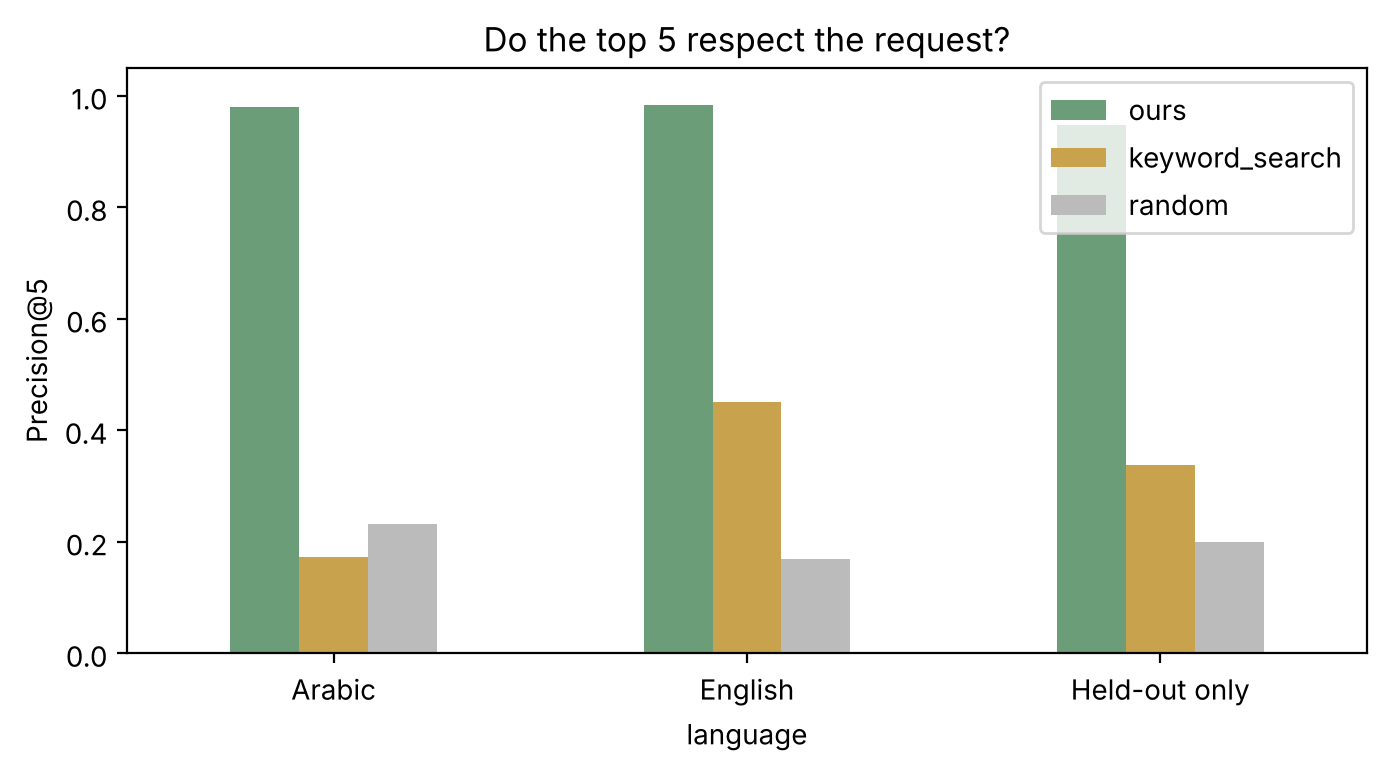

,query,set,ours
35,عطني شي للاسبرسو فيه كاكاو وبندق,held-out,0.6
39,ابي قهوة خفيفة زهرية للكيمكس,held-out,0.8
43,something with blueberry and dark chocolate,held-out,0.6


In [41]:
ax = precision_table.loc[["Arabic", "English", "Held-out only"]].plot(kind="bar", figsize=(8, 3.8),
                                                             color=[SAGE, GOLD, "#BBBBBB"], rot=0)
ax.set_ylabel("Precision@5")
ax.set_ylim(0, 1.05)
ax.set_title("Do the top 5 respect the request?")
plt.show()

ranking[ranking["ours"] < 1][["query", "set", "ours"]]

### 28.3 Focus test

When the user picks a coffee and says what they liked, the results should follow that focus. I take 100 random in-stock coffees and check the top 5 for each focus.

**Model selection:** the focus factor (how many times more the chosen block counts) is tried at 1, 2, 4, 8 and 16 on the **first 50** coffees. For each focus I average two things: does the top 5 follow the focus, and does it still keep the taste. The score keeps rising a tiny bit, so I take the **smallest factor within 0.01 of the best**: a bigger factor would almost ignore everything else for no real gain. The table is then reported on the **other 50** coffees.

In [42]:
def focus_test(coffee_ids):
    rows = []
    for focus, check in checks.items():
        ours, taste, random_share = [], [], []
        for cid in coffee_ids:
            ref = rec.COFFEES[rec.BY_ID[cid]]
            if not applies(focus, ref):
                continue
            results = [rec.COFFEES[rec.BY_ID[r["coffee_id"]]] for r in rec.similar(cid, focus=focus, lang="en")["results"]]
            ours += [check(ref, c) for c in results]
            taste += [same_taste(ref, c) for c in results]
            random_share += [check(ref, rec.COFFEES[rec.BY_ID[x]]) for x in rng.choice(in_stock_ids, 5)]
        rows.append({"focus": focus, "ours": np.mean(ours), "taste_kept": np.mean(taste), "random": np.mean(random_share)})
    return pd.DataFrame(rows).set_index("focus").round(3)


factor_rows = []
for factor in [1, 2, 4, 8, 16]:
    rec.FOCUS_FACTOR = factor
    table = focus_test(tune_ids).drop("flavor")
    factor_rows.append({"focus_factor": factor, "follows_focus": table["ours"].mean(),
                        "taste_kept": table["taste_kept"].mean(),
                        "score": ((table["ours"] + table["taste_kept"]) / 2).mean()})
factor_tuning = pd.DataFrame(factor_rows).round(3)
best_score = factor_tuning["score"].max()
best_factor = int(factor_tuning[factor_tuning["score"] >= best_score - 0.01]["focus_factor"].min())
rec.FOCUS_FACTOR = best_factor
print(factor_tuning.to_string(index=False))
print("Chosen focus factor:", best_factor)

focus_table = focus_test(test_ids)
focus_table

 focus_factor  follows_focus  taste_kept  score
            1          0.710       0.849  0.780
            2          0.795       0.842  0.819
            4          0.905       0.840  0.872
            8          0.969       0.826  0.897
           16          0.990       0.819  0.904
Chosen focus factor: 8


,ours,taste_kept,random
focus,,,
origin,0.995,0.787,0.118
process,0.983,0.804,0.330
price,1.000,0.789,0.532
body,0.860,0.910,0.160
flavor,0.916,0.916,0.564


### 28.4 Variety and speed

In [43]:
seen, roaster_counts, times = set(), [], []
queries = [t["q"] for t in tests + held_out]
for cid in sample_ids:
    start = time.perf_counter()
    results = rec.similar(cid, focus="overall", lang="en")["results"]
    times.append(time.perf_counter() - start)
    seen |= {r["coffee_id"] for r in results}
    roaster_counts.append(len({r["roaster"] for r in results}))
for q in queries:
    start = time.perf_counter()
    results = rec.recommend(q, lang="en")["results"]
    times.append(time.perf_counter() - start)
    seen |= {r["coffee_id"] for r in results}

coverage = len(seen) / len(in_stock_ids)
print("Different coffees shown at least once:", len(seen), "of", len(in_stock_ids), f"({coverage:.0%})")
print("Average different roasters in a top 5:", round(np.mean(roaster_counts), 2))
print("Average time per request:", round(np.mean(times) * 1000, 1), "ms")

Different coffees shown at least once: 343 of 518 (66%)
Average different roasters in a top 5: 4.6
Average time per request: 9.5 ms


In [44]:
real_prices = df[df["price_was_filled"] == 0]
report["data"] = {
    "n_coffees": int(len(df)), "n_roasters": int(df["roaster"].nunique()),
    "n_sites": int(df["source_domain"].nunique()),
    "n_cities": int(df.loc[df["roaster_city"] != "Unknown", "roaster_city"].nunique()),
    "missing_before": 8672, "translations": int(len(translations)),
    "top_origins": df["origin_country"].value_counts().head(8).to_dict(),
    "process": df["process"].value_counts().to_dict(),
    "families": {f: int(family_final[f].sum()) for f in families},
    "median_price_100g": float(real_prices["price_per_100g_sar"].median()),
    "price_hist": np.histogram(real_prices["price_per_100g_sar"].clip(upper=60), bins=12, range=(0, 60))[0].tolist(),
    "continent_median": {c: float(real_prices.loc[real_prices["origin_continent"] == c, "price_per_100g_sar"].median())
                         for c in ["Africa", "Latin America", "Asia", "Arabian Peninsula"]},
    "in_stock": len(in_stock_ids),
}
generic_notes = {"Fruity", "Fruits", "Floral", "Sweetness", "Sweet", "Nuts", "Citrus", "Spices", "Tea", "Aromatic",
                 "High sweetness", "Fruity aroma", "Floral hint", "Floral hints"}
wheel = {}
for f in families:
    members = [i for i in df.index if has_notes[i] and family_final.loc[i, f] == 1]
    counts = pd.Series([n for i in members for n in df.loc[i, "notes_list"]
                        if f in rec.NOTE_FAMILIES.get(n, []) and n not in generic_notes]).value_counts()
    wheel[f] = {"count": int(family_final[f].sum()),
                "notes": [[n, int(c), rec.NOTE_AR.get(n, n)] for n, c in counts.head(4).items()]}
report["data"]["wheel"] = wheel
report["twin_test"] = twin_results.reset_index().replace({np.nan: None}).to_dict(orient="records")
report["understanding"] = {"dev_all_correct": float(dev_all), "heldout_all_correct": float(test_all),
                           "dev_fields": dev_fields.round(3).to_dict(), "heldout_fields": test_fields.round(3).to_dict(),
                           "n_dev": len(tests), "n_heldout": len(held_out)}
report["precision"] = precision_table.round(3).to_dict(orient="index")
report["focus"] = focus_table.to_dict(orient="index")
report["variety"] = {"coverage": coverage, "shown": len(seen), "roasters_in_top5": float(np.mean(roaster_counts)),
                     "ms_per_request": float(np.mean(times) * 1000)}

# the chosen KNN settings go to the API
knn_meta["weights"] = dict(rec.WEIGHTS)
knn_meta["focus_factor"] = best_factor
with open("../models/knn_meta.json", "w", encoding="utf-8") as f:
    json.dump(knn_meta, f, ensure_ascii=False)
report["knn"] = {"weights": dict(rec.WEIGHTS), "focus_factor": best_factor,
                 "weight_tuning": weight_tuning.to_dict(orient="records"),
                 "factor_tuning": factor_tuning.to_dict(orient="records"),
                 "blocks": {b: bounds[b][1] - bounds[b][0] for b in block_names},
                 "n_imputed_notes": int((~has_notes).sum()), "n_body_from_rf": int(unknown_body.sum()),
                 "notes_weight": notes_weight, "similar_test": similar_scores(test_ids)}

with open("../models/report.json", "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=1, default=float)
print("Saved models/report.json")

Saved models/report.json


## 29. Model Selection Summary

| Part | Type | What I compared | Metric (and why) | Result | Choice |
|---|---|---|---|---|---|
| **Recommender** | **Unsupervised: K-Nearest Neighbors** (cosine) | notes vs families mix; attribute weight 0.1 to 1; focus factor 1 to 16 | twin test Hit@5; precision@5 on development requests + "taste kept" on tuning coffees; focus test on tuning coffees | twin Hit@5 0.28 vs 0.09 random; dev precision 1.0; follows the focus 97% at ×8 | **KNN, notes 70% / families 30%, other blocks 0.25 each, focus ×8** |
| Flavor of the 42 coffees with no notes | Supervised, multi-label | Baseline, Logistic Regression, Random Forest, Gradient Boosting | ROC-AUC with roaster-grouped CV (imbalanced yes/no labels) | RF 0.69, LR 0.67, GB 0.66, baseline 0.43 | **Random Forest** (feeds the KNN families block) |
| Body of the 397 coffees without it | Supervised, 3 classes | 2 baselines, Logistic Regression, Random Forest, Gradient Boosting, Naive Bayes | Macro F1 (imbalanced classes) + log loss (we use the probabilities) | Macro F1 about 0.38 to 0.39 vs 0.24; RF best log loss (1.03); 76% right when 50%+ sure | **Random Forest** (its probabilities feed the KNN body block) |
| Notes of the 42 coffees | Unsupervised imputation | | | notes borrowed from the 10 nearest coffees | **KNNImputer** |
| Coffee personalities | Unsupervised | K-Means with k = 2 to 8 | Silhouette, with max 6 cards for usability | k = 6, silhouette 0.40 | **K-Means, k = 6** |
| Acidity and bitterness | Taste scores from `02_Modeling` | (very few labels: 72 and 21) | Spearman against the coffees that state them (acidity 0.26, p = 0.03) | weak but in the right direction | **Stated value, otherwise the score's thirds**, marked "estimated" |
| Understanding requests | Rules + fuzzy name matching | Development vs held-out requests | Share of requests with every field right | 40/40 development, **22/22 held-out** | |
| **Final ranking test** | | KNN vs keyword search vs random | Precision@5 on the 22 held-out requests | **0.95** vs 0.34 vs 0.20 | |

## 30. Conclusion

**What we built:** مَذاق recommends 5 coffees out of 518 in stock, with a reason for each, from a sentence in Arabic or English, from a coffee you liked, or from a personality card. The core is **K-Nearest Neighbors**: the request becomes a point in the same space as the coffees, and we return the closest ones. The supervised Random Forests and the KNN imputer fill the missing parts of that space, and K-Means builds the personality cards. It answers in about 9 ms, so it runs easily on a free server.

**What the evaluation shows:**
- It **understands** requests very well: every field was right on 22 new requests it had never seen.
- Its top 5 **respect the request** 95% of the time on those new requests (98% on all of them), against 34% for a normal keyword search. The gap is biggest in Arabic (0.98 vs 0.17), because a keyword search can't match Arabic words against English data.
- When you pick a coffee and a focus, the results **follow that focus** on coffees not used for tuning: same origin 99%, same process 98%, same price or cheaper 100%, same body 86%, while still keeping the taste 79% to 92% of the time.
- It shows **variety**: 66% of the in-stock coffees appear in at least one top 5, from about 4.6 different roasters each time.
- On an **independent test** written by Daniyah (31 requests, `05_Evaluation`), it understood 77% on the first try; the misses were bitterness and English typos, which we then added.

**Limitations (honest):**
1. We have **no user feedback**, so we can't measure whether people actually *like* the coffees we suggest. The next step is a 👍/👎 button in the app. With enough feedback, the recommender could become a supervised ranking model.
2. **TF-IDF treats words as different even when they mean almost the same** (*Cocoa* vs *Chocolate*). The families block helps, but a smarter text representation would help more.
3. **Body, acidity and bitterness are weak.** The labels are missing or inconsistent between roasters, so body mostly comes from the Random Forest probabilities, and acidity and bitterness are estimated taste scores (only 21 coffees, all from one roaster, state their bitterness).
4. The test requests were written by our team. Real users will write things we didn't think of, and new words need to be added to the lexicon.
5. 149 prices are estimates (`Coffee_EDA` section 15.1), and stock status is from the day the data was collected.